In [ ]:
# ============================================================
# Preparing Data
# ============================================================

In [2]:
# ============================================================
# Imports
# ============================================================
import os
import warnings
import re
import random
import pickle
from pathlib import Path
from collections import defaultdict, OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

import mne
from mne.decoding import (SlidingEstimator, LinearModel, get_coef,
                          cross_val_multiscore)

from scipy.stats import ttest_rel, ttest_1samp
from scipy.signal import windows

from statsmodels.formula.api import mixedlm
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import acf

import pingouin as pg

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV

from pymer4.models import Lmer

from tqdm import tqdm

# Keep the output free of package warnings and MNE file-reading messages
warnings.filterwarnings("ignore")
mne.set_log_level("WARNING")


In [3]:
# ============================================================
# Session info: software versions
# Put this cell directly after the Imports cell. Running it
#   (1) prints the versions used for every analysis, so they are saved in the
#       notebook output, and
#   (2) writes requirements.txt and environment.yml next to the notebook with
#       those exact versions pinned.
# Re-run it whenever you update packages, then commit the two files.
# ============================================================
import platform
import sys
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path

# Python packages imported anywhere in the notebook (pip distribution names)
PACKAGES = [
    "numpy", "pandas", "scipy", "matplotlib", "mne", "scikit-learn",
    "statsmodels", "pingouin", "pymer4", "rpy2", "tqdm",
    "jupyterlab", "ipykernel",           # to open and run the notebook
]

versions = {}
for pkg in PACKAGES:
    try:
        versions[pkg] = version(pkg)
    except PackageNotFoundError:
        versions[pkg] = None

# R and lme4 (used by pymer4 for the behavioral GLMM)
try:
    import rpy2.robjects as ro
    r_version = str(ro.r("paste(R.version$major, R.version$minor, sep='.')")[0])
    lme4_version = str(ro.r("as.character(packageVersion('lme4'))")[0])
except Exception as err:                 # R not reachable from this kernel
    r_version, lme4_version = None, None
    print(f"Could not query R: {err}")

py_version = platform.python_version()

print(f"Python        {py_version}  ({platform.platform()})")
for pkg, v in versions.items():
    print(f"{pkg:<14}{v if v else 'not installed'}")
print(f"R             {r_version}")
print(f"lme4          {lme4_version}")

# ---- requirements.txt (pip) ----
req_lines = [
    f"# Python {py_version}",
    f"# R {r_version} with lme4 {lme4_version} is also required (behavioral GLMM via pymer4)",
]
req_lines += [f"{pkg}=={v}" for pkg, v in versions.items() if v]
Path("requirements.txt").write_text("\n".join(req_lines) + "\n")

# ---- environment.yml (conda; installs R and lme4 as well) ----
# Packages are installed from conda-forge where possible. If `conda env create`
# cannot solve an exact pin, relax that one line to its minor version (e.g. 1.26.*).
conda_names = {"scikit-learn": "scikit-learn", "rpy2": "rpy2"}
env_lines = [
    "name: acousticcueseeg",
    "channels:",
    "  - conda-forge",
    "dependencies:",
    f"  - python={py_version}",
]
if r_version:
    env_lines.append(f"  - r-base={r_version}")
if lme4_version:
    env_lines.append(f"  - r-lme4={lme4_version}")
PIP_ONLY = {"pymer4"}                    # installed with pip inside the conda env
env_lines += [f"  - {conda_names.get(pkg, pkg)}={v}"
              for pkg, v in versions.items() if v and pkg not in PIP_ONLY]
pip_pins = [f"      - {pkg}=={versions[pkg]}" for pkg in PIP_ONLY if versions.get(pkg)]
if pip_pins:
    env_lines += ["  - pip", "  - pip:"] + pip_pins
Path("environment.yml").write_text("\n".join(env_lines) + "\n")

print("\nWrote requirements.txt and environment.yml")

Python        3.14.2  (macOS-14.4.1-arm64-arm-64bit-Mach-O)
numpy         2.3.5
pandas        2.3.3
scipy         1.16.3
matplotlib    3.10.8
mne           1.11.0
scikit-learn  1.7.2
statsmodels   0.14.6
pingouin      0.6.1
pymer4        0.8.2
rpy2          3.6.4
tqdm          4.67.1
jupyterlab    not installed
ipykernel     7.1.0
R             4.5.2
lme4          2.0.1

Wrote requirements.txt and environment.yml


In [4]:
# Prepare the epochs for analysis

# Define the path to your folder containing the epoch files
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))

# Containers for data
evokeds_list3 = []

# Loop over each epoch file
for epoch_file in epoch_files:
    participant_id = epoch_file.stem.split("-epo")[0]
    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)

    # Create new column for 'target-voice' classification
    epochs.metadata["target-voice"] = epochs.metadata["target"].apply(
        lambda w: "voiced" if w in ["dear", "beach"] else "voiceless")

    # Filter by 'task-relevant' field
    for task_label in ['yes', 'no']:
        task_subset = epochs[epochs.metadata["task-relevant"] == task_label]

        # --- Steps from target (VOT and F0) ---
        for vot in task_subset.metadata["vot-stepsfromtarget"].unique():
            for f0 in task_subset.metadata["f0-stepsfromtarget"].unique():
                for voice in task_subset.metadata["target-voice"].unique():
                    mask = (
                        (task_subset.metadata["vot-stepsfromtarget"] == vot) &
                        (task_subset.metadata["f0-stepsfromtarget"] == f0) &
                        (task_subset.metadata["target-voice"] == voice))
                    vot_f0_subset = task_subset[mask]
                    if len(vot_f0_subset) == 0:
                        continue
    
                    evoked3 = vot_f0_subset.average()
                    evoked3.comment = f"subj-{participant_id}_task-{task_label}_VOT-{vot}_F0-{f0}_voice-{voice}"
                    evokeds_list3.append(evoked3)


In [5]:
# === EXCLUSION CRITERIA ===
# A participant is excluded if they meet either criterion:
#   1. Accuracy: below 50% "target" responses to the prototypical voiced token
#      (VOT 1, f0 1) OR to the prototypical voiceless token (VOT 5, f0 5), on
#      task-relevant trials.
#   2. Bad channels: more than 3 of 30 EEG channels (10%) marked bad during preprocessing.
# Criteria are applied in that order. Participants who fail both are reported
# under accuracy, but every failed criterion is listed in the table.

# === SETTINGS ===
min_accuracy = 0.5        # minimum proportion of "target" responses to each prototypical token
max_bad_channels = 3

mne.set_log_level("WARNING")

# === PATHS ===
epochs_folder = Path(os.getcwd()) / "epochs"
log_folder = Path(os.getcwd()) / "logs"

epoch_files = sorted(epochs_folder.glob("*-epo.fif"))
log_files = sorted(log_folder.glob("*.log"))

def clean_id(s):
    return s.replace("subj-", "").strip()

# === ACCURACY ON PROTOTYPICAL TOKENS ===
behavior_summary = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    md = mne.read_epochs(epoch_file, preload=False, verbose=False).metadata

    md = md[md["task-relevant"] == "yes"].copy()
    md["target-voice"] = np.where(md["target"].isin(["dear", "beach"]), "voiced", "voiceless")
    said_target = md["oddball_response.keys"] == "n"   # missing responses count as incorrect

    mask_voiced = (md["target-voice"] == "voiced") & (md["VOT"] == 1) & (md["F0"] == 1)
    mask_voiceless = (md["target-voice"] == "voiceless") & (md["VOT"] == 5) & (md["F0"] == 5)

    behavior_summary.append({
        "participant": participant_id,
        "acc_voiced": said_target[mask_voiced].mean() if mask_voiced.any() else 0,
        "acc_voiceless": said_target[mask_voiceless].mean() if mask_voiceless.any() else 0,
        "n_epochs": len(md),
    })

behavior_df = pd.DataFrame(behavior_summary)

# === BAD CHANNELS FROM LOGS ===
channels_summary = []

for log_file in log_files:
    final_bad_channels = []
    with open(log_file, "r") as f:
        for line in f:
            if "Bad channels" in line:
                channels = re.findall(r"'(.*?)'|\"(.*?)\"", line)
                final_bad_channels = [c[0] if c[0] else c[1] for c in channels]
    channels_summary.append({
        "participant": clean_id(log_file.stem),
        "n_bad_channels": len(final_bad_channels),
    })

channels_df = pd.DataFrame(channels_summary)

# === APPLY EXCLUSION CRITERIA ===
summary_df = behavior_df.merge(channels_df, on="participant", how="outer").sort_values("participant")

fail_voiced = summary_df["acc_voiced"] < min_accuracy
fail_voiceless = summary_df["acc_voiceless"] < min_accuracy
fail_accuracy = fail_voiced | fail_voiceless
fail_channels = summary_df["n_bad_channels"] > max_bad_channels

def reasons(row_idx):
    r = []
    if fail_voiced[row_idx]:
        r.append(f"accuracy, voiced token ({summary_df.at[row_idx, 'acc_voiced']:.0%})")
    if fail_voiceless[row_idx]:
        r.append(f"accuracy, voiceless token ({summary_df.at[row_idx, 'acc_voiceless']:.0%})")
    if fail_channels[row_idx]:
        r.append(f"bad channels ({summary_df.at[row_idx, 'n_bad_channels']})")
    return "; ".join(r)

summary_df["exclude"] = fail_accuracy | fail_channels
summary_df["reason"] = [reasons(i) for i in summary_df.index]
summary_df["counted_under"] = np.select([fail_accuracy, fail_channels], ["accuracy", "bad channels"], default="")

excluded = summary_df.loc[summary_df["exclude"], "participant"].tolist()
included = summary_df.loc[~summary_df["exclude"], "participant"].tolist()

# === APPLY TO EVOKEDS (built in the data-preparation cell) ===
evokeds_list3 = [
    evk for evk in evokeds_list3
    if evk.comment.split("_")[0].split("-")[1] not in excluded
]

# === OUTPUT ===
print("Excluded participants and reasons:")
print(summary_df.loc[summary_df["exclude"],
                     ["participant", "acc_voiced", "acc_voiceless", "n_bad_channels", "counted_under", "reason"]]
      .round(2).to_string(index=False))

print(f"\nExcluded for accuracy: {(summary_df['counted_under'] == 'accuracy').sum()} "
      f"(voiced: {fail_voiced.sum()}, voiceless: {fail_voiceless.sum()})")
print(f"Excluded for bad channels (accuracy OK): {(summary_df['counted_under'] == 'bad channels').sum()}")
print(f"Total excluded: {len(excluded)} | Total included: {len(included)}")
print("Included:", included)

Excluded participants and reasons:
participant  acc_voiced  acc_voiceless  n_bad_channels counted_under                                                        reason
        108        0.47           1.00               5      accuracy                accuracy, voiced token (47%); bad channels (5)
        109        0.67           0.94               4  bad channels                                              bad channels (4)
        114        0.80           1.00               5  bad channels                                              bad channels (5)
        115        0.84           0.89               7  bad channels                                              bad channels (7)
        117        0.45           0.95               0      accuracy                                  accuracy, voiced token (45%)
        119        0.42           0.47               0      accuracy accuracy, voiced token (42%); accuracy, voiceless token (47%)
        121        0.44           1.00          

In [ ]:
# ============================================================
# Analysis 0: Behavioral data
# ============================================================

Linear mixed model fit by maximum likelihood  ['lmerMod']
Formula: resp~vot_tgt_center*f0_tgt_center+(vot_tgt_center*f0_tgt_center||participant)

Family: binomial	 Inference: parametric

Number of observations: 17968	 Groups: {'participant': 30.0}

Log-likelihood: -7757.391 	 AIC: 15530.781

Random effects:

                                       Name    Var    Std
participant                     (Intercept)  0.199  0.446
participant.1                vot_tgt_center  0.221  0.470
participant.2                 f0_tgt_center  0.046  0.215
participant.3  vot_tgt_center:f0_tgt_center  0.012  0.111

No random effect correlations specified

Fixed effects:

Fixed effects:
                               Estimate Std. Error  z value  Pr(>|z|)
(Intercept)                     0.32800    0.08400    3.896   < 2e-16 ***
vot_tgt_center                  1.38400    0.08800   15.692   < 2e-16 ***
f0_tgt_center                   0.51100    0.04700   10.849   < 2e-16 ***
vot_tgt_center:f0_tgt_center   -0.0

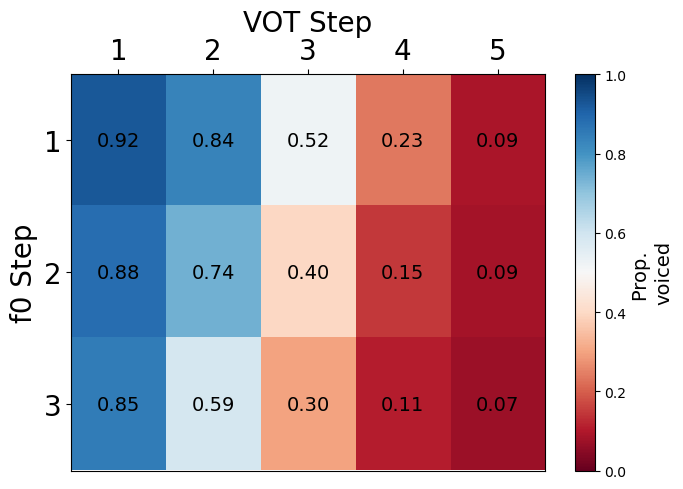

In [6]:
# =========================================================
# Oddball behavioral analysis  (Python port of oddball.R)
# =========================================================

# ---------------------------------------------------------
# Reference data (embedded — replaces Reference.csv/.xlsx)
# Joined to the behavioral data on audio_clip (== "Sound" in R)
# ---------------------------------------------------------
reference = pd.DataFrame({
    "audio_clip": [
        "Stimuli_channel3/bp1_1.wav", "Stimuli_channel3/bp1_3.wav", "Stimuli_channel3/bp1_5.wav",
        "Stimuli_channel3/bp2_1.wav", "Stimuli_channel3/bp2_3.wav", "Stimuli_channel3/bp2_5.wav",
        "Stimuli_channel3/bp3_1.wav", "Stimuli_channel3/bp3_3.wav", "Stimuli_channel3/bp3_5.wav",
        "Stimuli_channel3/bp4_1.wav", "Stimuli_channel3/bp4_3.wav", "Stimuli_channel3/bp4_5.wav",
        "Stimuli_channel3/bp5_1.wav", "Stimuli_channel3/bp5_3.wav", "Stimuli_channel3/bp5_5.wav",
        "Stimuli_channel3/dt1_1.wav", "Stimuli_channel3/dt1_3.wav", "Stimuli_channel3/dt1_5.wav",
        "Stimuli_channel3/dt2_1.wav", "Stimuli_channel3/dt2_3.wav", "Stimuli_channel3/dt2_5.wav",
        "Stimuli_channel3/dt3_1.wav", "Stimuli_channel3/dt3_3.wav", "Stimuli_channel3/dt3_5.wav",
        "Stimuli_channel3/dt4_1.wav", "Stimuli_channel3/dt4_3.wav", "Stimuli_channel3/dt4_5.wav",
        "Stimuli_channel3/dt5_1.wav", "Stimuli_channel3/dt5_3.wav", "Stimuli_channel3/dt5_5.wav",
    ],
    "Continuum": ["beach - peach"] * 15 + ["dear - tear"] * 15,
    "F0":  [1, 3, 5] * 10,
    "VOT": [1, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 5] * 2,
})

# ---------------------------------------------------------
# Importing and combining the per-participant CSV files
# ---------------------------------------------------------
behavior_folder = Path(os.getcwd()) / "behavior/"
csv_files = sorted(behavior_folder.glob("*_ob.csv"))

data = pd.concat(
    [pd.read_csv(f, dtype={"participant": str}) for f in csv_files],
    ignore_index=True,
)

# Add reference data (left join, R: by = c("audio_clip" = "Sound"))
data = data.merge(reference, on="audio_clip", how="left")

# Derive targetVoice
data["targetVoice"] = np.where(
    data["target"].isin(["dear", "beach"]), "voiced", "voiceless"
)

# Mark whether the target belongs to the presented continuum
data["relevant"] = data.apply(
    lambda r: "relevant"
    if isinstance(r["Continuum"], str) and r["target"] in r["Continuum"].split(" - ")
    else "notRelevant",
    axis=1,
)

# Exclude participants (behavioral exclusions from oddball.R;
# kept separate from the EEG `excluded`/`included` lists defined above)
behavior_excluded = [101, 102, 103, 104, 118, 122, 126, 108, 109,
                     114, 115, 117, 119, 121, 133, 138, 144]
data = data[~data["participant"].isin([str(p) for p in behavior_excluded])]

# ---------------------------------------------------------
# Relabel so that higher = more target-like
# ---------------------------------------------------------
data["vot_tgt"] = np.where(data["targetVoice"] == "voiced", 6 - data["VOT"], data["VOT"])
data["f0_tgt"]  = np.where(data["targetVoice"] == "voiced", 6 - data["F0"],  data["F0"])

# Compress F0 levels: 1 -> 1, 3 -> 2, 5 -> 3
f0_recode = {1: 1, 3: 2, 5: 3}
data["F0"]     = data["F0"].map(f0_recode).astype("category")
data["VOT"]    = data["VOT"].astype("category")
data["f0_tgt"] = data["f0_tgt"].map(f0_recode).astype("category")

# Keep only valid keypress responses
data = data[data["oddball_response.keys"].isin(["m", "n"])]

data_full = data.copy()
data = data[data["relevant"] == "relevant"]

# ---------------------------------------------------------
# Center predictors
# ---------------------------------------------------------
data["vot_tgt_center"] = data["vot_tgt"].astype(float) - data["vot_tgt"].astype(float).mean()
data["f0_tgt_center"]  = data["f0_tgt"].astype(float) - data["f0_tgt"].astype(float).mean()

data["participant"] = data["participant"].astype("category")

# ---------------------------------------------------------
# Logistic regression (GLMM)
# R modeled as.factor(keys) (alphabetical -> reference "m", models P("n"))
# ---------------------------------------------------------
data["resp"] = (data["oddball_response.keys"] == "n").astype(int)

glm_stops = Lmer(
    "resp ~ vot_tgt_center * f0_tgt_center + (vot_tgt_center * f0_tgt_center || participant)",
    data=data,
    family="binomial",
)
res = glm_stops.fit()


# ---- Print fixed effects in R summary() style ----
def _sig_stars(p):
    if p < 0.001: return "***"
    if p < 0.01:  return "**"
    if p < 0.05:  return "*"
    if p < 0.1:   return "."
    return ""

def _fmt_p(p):
    if p < 2e-16: return "< 2e-16"
    if p < 1e-4:  return f"{p:.2e}"
    return f"{p:.3g}"

def print_fixef(res):
    # pymer4 column names for a binomial GLMM
    est = res["Estimate"]
    se  = res["SE"]
    z   = res["Z-stat"]
    p   = res["P-val"]

    name_w = max(len(str(i)) for i in res.index)
    print("Fixed effects:")
    header = (f"{'':<{name_w}} {'Estimate':>10} {'Std. Error':>10} "
              f"{'z value':>8} {'Pr(>|z|)':>9}")
    print(header)
    for term in res.index:
        stars = _sig_stars(p[term])
        print(f"{term:<{name_w}} {est[term]:>10.5f} {se[term]:>10.5f} "
              f"{z[term]:>8.3f} {_fmt_p(p[term]):>9} {stars}")
    print("---")
    print("Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1")

print_fixef(res)

# ---------------------------------------------------------
# Figure
# ---------------------------------------------------------
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

data_summary2 = (
    data.dropna(subset=["vot_tgt", "f0_tgt"])
    .groupby(["vot_tgt", "f0_tgt"], observed=True)
    .apply(lambda g: (g["oddball_response.keys"] == "m").mean())
    .reset_index(name="prop_m")
)
data_summary2["f0_tgt"]  = data_summary2["f0_tgt"].astype(int)
data_summary2["vot_tgt"] = data_summary2["vot_tgt"].astype(int)

pivot = (
    data_summary2.pivot(index="f0_tgt", columns="vot_tgt", values="prop_m")
    .sort_index(ascending=True)  # reversed order: lowest f0 on top
)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(pivot.values, cmap="RdBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns, fontsize=20)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index, fontsize=20)
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()
ax.set_xlabel("VOT Step", fontsize=20)
ax.set_ylabel("f0 Step", fontsize=20)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=14, color="black")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Prop. \nvoiced", fontsize=14)
plt.tight_layout()
fig.savefig(figures_folder / "behavior_tile.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Analysis 1: Amplitude differences
# ============================================================

Figure saved: VOT_steps_comparison.png


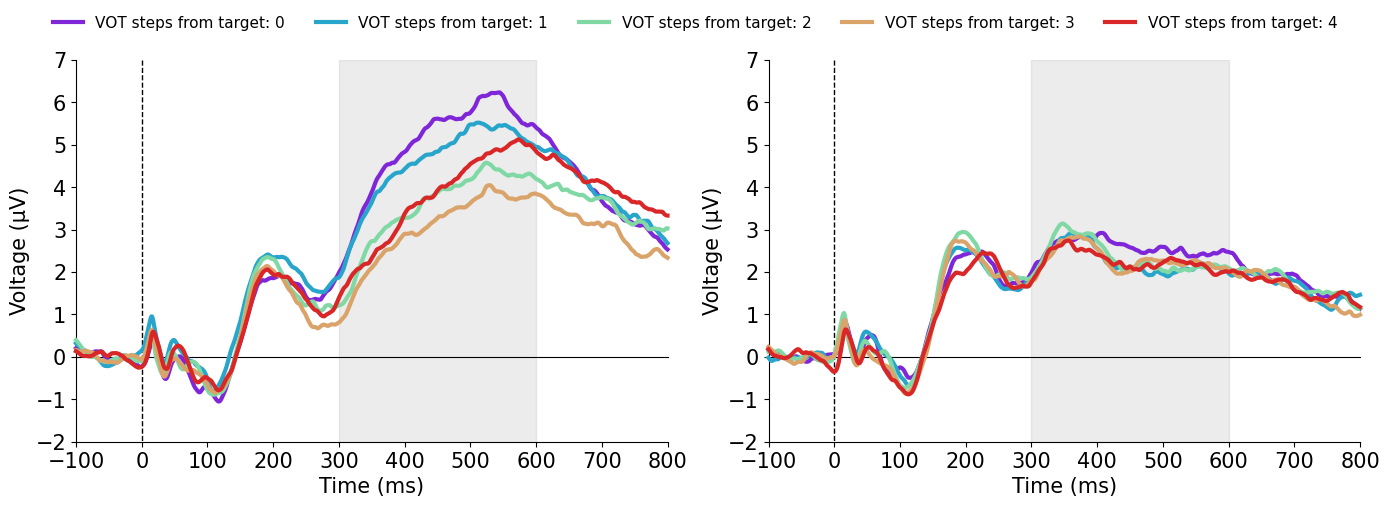

Figure saved: F0_steps_comparison.png


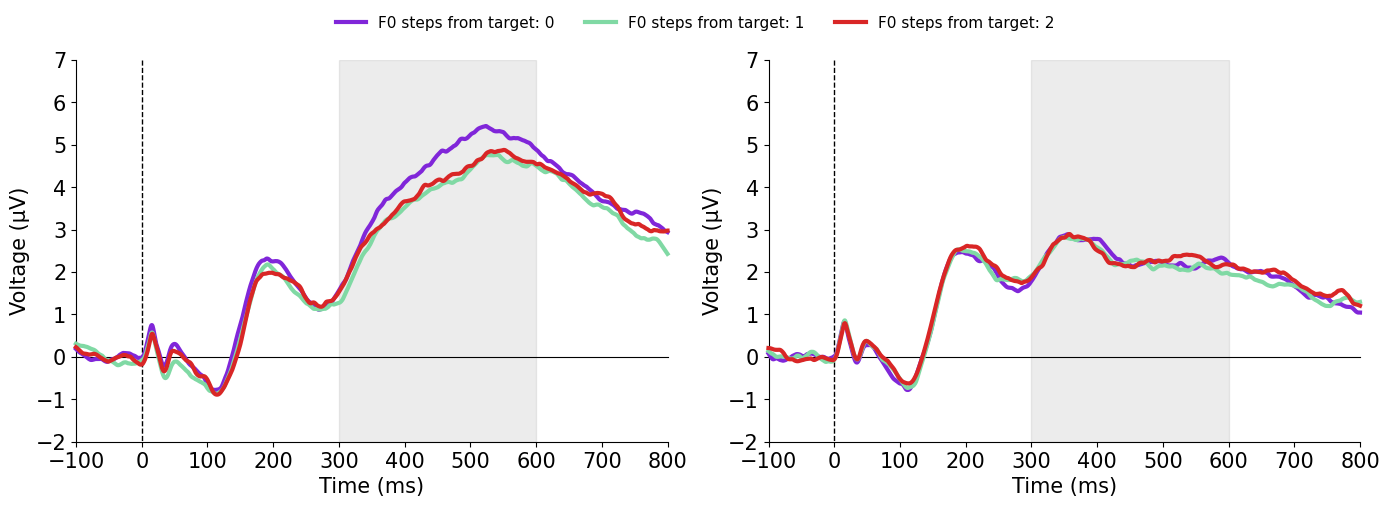

Participants included in LMM data: 30
                      Mixed Linear Model Regression Results
Model:                     MixedLM        Dependent Variable:        mean_voltage
No. Observations:          17300          Method:                    REML        
No. Groups:                30             Scale:                     118.4935    
Min. group size:           488            Log-Likelihood:            -65903.7381 
Max. group size:           600            Converged:                 Yes         
Mean group size:           576.7                                                 
---------------------------------------------------------------------------------
                                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
---------------------------------------------------------------------------------
Intercept                               5.991    0.583 10.276 0.000  4.849  7.134
vot_stepsfromtarget                    -0.559    0.122 -4.578 0.000 -0.798 -0.320


In [7]:
# -------------------------------------------------------
# P3 by steps from target: VOT and F0
# -------------------------------------------------------

figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

P3_WIN_MS = (300, 600)     # shaded analysis window

def muted_rainbow(n):
    cs = plt.cm.rainbow(np.linspace(0, 1, n))
    return [(c[0]*0.7+0.15, c[1]*0.7+0.15, c[2]*0.7+0.15, c[3]) for c in cs]

def plot_steps_from_target(cue, step_label, save_name):
    """cue = 'VOT' or 'F0'; step_label maps the metadata code to the plotted step."""
    tasks_list = sorted({re.search(r'task-([\w]+)', e.comment).group(1)
                         for e in evokeds_list3 if re.search(r'task-([\w]+)', e.comment)})
    if len(tasks_list) < 2:
        return
    if 'no_VOT' in tasks_list and 'yes_VOT' in tasks_list:
        tasks_list = ['yes_VOT', 'no_VOT']        # task-relevant left, task-irrelevant right

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    legend_lines = None

    for ax, task in zip(axes, tasks_list[:2]):
        # Group by steps from target for this cue
        step_groups = defaultdict(list)
        for evk in evokeds_list3:
            if f"task-{task}" not in evk.comment:
                continue
            match = re.search(rf'{cue}-([\d]+)', evk.comment)
            if match:
                step_groups[f"{cue} steps from target: {step_label(int(match.group(1)))}"].append(evk)
        ordered = OrderedDict(sorted(step_groups.items(), key=lambda x: int(x[0].split()[-1])))

        mne.viz.plot_compare_evokeds(ordered, combine='mean', picks=['Pz', 'P3', 'P4'], title="",
                                     cmap=None, axes=ax, ylim=dict(eeg=[-2, 7]), legend=False,
                                     time_unit="ms", ci=False, show=False)
        while len(fig.axes) > 2:                      # remove any extra axes (e.g. colorbars)
            fig.axes[2].remove()

        colors = muted_rainbow(len(ordered))
        for i, line in enumerate(ax.lines[:len(colors)]):
            line.set_color(colors[i]); line.set_linewidth(3)
        if legend_lines is None:
            legend_lines = [mlines.Line2D([0], [0], color=colors[i], lw=3, label=lab)
                            for i, lab in enumerate(ordered)]
        if ax.get_legend() is not None:
            ax.get_legend().remove()

        ax.axvspan(*P3_WIN_MS, color='grey', alpha=0.15, zorder=0)   # analysis window
        ax.set_xlabel("Time (ms)", fontsize=15)
        ax.set_ylabel("Voltage (µV)", fontsize=15)
        ax.tick_params(axis='both', labelsize=15)
        ax.set_xticks(range(-100, 801, 100))
        ax.spines['bottom'].set_bounds(-100, 800)
        ax.set_xlim(-100, 800)

    fig.legend(handles=legend_lines, loc='upper center', ncol=len(legend_lines),
               bbox_to_anchor=(0.5, 1.02), frameon=False, fontsize=11)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    save_path = figures_folder / save_name
    fig.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0.1)
    print(f"Figure saved: {save_path.name}")
    plt.show()

# VOT: metadata 1-5 -> steps 0-4
plot_steps_from_target("VOT", lambda v: v - 1, "VOT_steps_comparison.png")

# F0: metadata 1/3/5 -> steps 0/1/2
plot_steps_from_target("F0", {1: 0, 3: 1, 5: 2}.get, "F0_steps_comparison.png")

# -------------------------------------------------------
# LMM: prepare trial-level data
# -------------------------------------------------------

tmin, tmax = 0.3, 0.6
picks_parietal = ["Pz", "P3", "P4"]
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))

lmm_data = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])

    if participant_id in excluded:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)

    if epochs.metadata is None:
        continue

    epochs.metadata["target-voice"] = epochs.metadata["target"].apply(
        lambda w: "voiced" if w in ["dear", "beach"] else "voiceless"
    )

    # Mean P3 amplitude per trial at parietal electrodes (300-600 ms window),
    # computed for all trials; task-relevant vs -irrelevant are split below
    epochs_crop = epochs.copy().pick(picks_parietal).crop(tmin=tmin, tmax=tmax)
    mean_voltage = epochs_crop.get_data().mean(axis=(1, 2))

    df = epochs.metadata.copy()
    df["mean_voltage"] = mean_voltage
    df["participant"] = participant_id

    lmm_data.append(df)

df_lmm = pd.concat(lmm_data, ignore_index=True)

# Convert to categorical
df_lmm["F0_step"]       = df_lmm["F0_step"].astype("category")
df_lmm["VOT_step"]      = df_lmm["VOT_step"].astype("category")
df_lmm["target_voice"]  = df_lmm["target-voice"].astype("category")
df_lmm["Continuum"]     = df_lmm["Continuum"].astype("category")
df_lmm["participant"]   = df_lmm["participant"].astype("category")
df_lmm["task_relevant"] = df_lmm["task-relevant"].astype("category")

df_lmm["mean_voltage"] *= 1e6

df_lmm["vot_stepsfromtarget"] = pd.to_numeric(df_lmm["vot-stepsfromtarget"], errors="coerce")
df_lmm["f0_stepsfromtarget"]  = pd.to_numeric(df_lmm["f0-stepsfromtarget"],  errors="coerce")

# List all included participants
participants_included = df_lmm["participant"].unique().tolist()
print("Participants included in LMM data:", len(participants_included))

# -------------------------------------------------------
# LMM: VOT and F0 steps from target (task-relevant trials)
# -------------------------------------------------------

df_lmm_relevant = df_lmm[df_lmm["task-relevant"] == "yes"]

model_interaction = mixedlm(
    "mean_voltage ~ vot_stepsfromtarget * f0_stepsfromtarget",
    df_lmm_relevant, groups=df_lmm_relevant["participant"],
)
print(model_interaction.fit().summary())

# -------------------------------------------------------
# LMM: task-irrelevant continua (control model)
# Confirms that the amplitude modulation is specific to
# task-relevant processing (cf. task-relevant model above).
# -------------------------------------------------------

df_lmm_irrelevant = df_lmm[df_lmm["task-relevant"] == "no"]

model_interaction_irrel = mixedlm(
    "mean_voltage ~ vot_stepsfromtarget * f0_stepsfromtarget",
    df_lmm_irrelevant, groups=df_lmm_irrelevant["participant"],
)
print(model_interaction_irrel.fit().summary())


In [ ]:
# ============================================================
# Analysis 2: Timecourse differences
# ============================================================

In [8]:
# -------------------------------------------------------
# Decoding: setup, model, and helper functions
# -------------------------------------------------------


root_dir = Path(os.getcwd()) / "decoding/"
epochs_dir = Path(os.getcwd()) / "epochs/"
epochs_path_template = str(epochs_dir / '{}-epo.fif')

os.makedirs(root_dir, exist_ok=True)

mdl = LogisticRegressionCV(cv=5, class_weight='balanced', max_iter=10000)
cv = 5
n_jobs = -1

seed = 42
np.random.seed(seed)
random.seed(seed)


def temporal_decoding(X, y, cv, n_jobs=1, mdl=None, scoring='accuracy', verbose=False):
    """
    Perform temporal decoding using a sliding estimator.

    Parameters
    ----------
    X : ndarray, shape (n_samples, n_features, n_times)
    y : ndarray, shape (n_samples,)
    cv : int or cross-validation generator
    n_jobs : int
    mdl : sklearn estimator, optional. Defaults to LogisticRegressionCV(cv=5).
    scoring : str. Defaults to 'accuracy'.
    verbose : bool

    Returns
    -------
    scores : ndarray, shape (n_times,)
    model : SlidingEstimator
    coeffs : ndarray, shape (n_sensors, n_times) or (n_classes, n_sensors, n_times)
    """
    clf = make_pipeline(StandardScaler(), LinearModel(mdl))
    model = SlidingEstimator(clf, n_jobs=n_jobs, scoring=scoring, verbose=verbose)

    scores = np.mean(cross_val_multiscore(model, X, y, cv=cv, n_jobs=n_jobs), axis=0)

    model.fit(X, y)
    coeffs = get_coef(model, 'patterns_', inverse_transform=True)

    if len(model.classes_) > 2:
        coeffs = coeffs.transpose(1, 0, 2)  # (n_classes, n_sensors, n_times)

    return scores, model, coeffs


def oleson_significance(all_scores, times, chance_level=0.5,
                        smoothing_ms=50, bin_ms=10, sfreq=1000,
                        alpha=0.05, alternative='greater'):
    """
    Sarrett & Toscano (2024) / Oleson et al. (2017) inspired group-level test.

    Parameters
    ----------
    all_scores : (n_subjects, n_times) array of decoding accuracy.
    times : (n_times,) time vector in seconds.
    chance_level : numerical chance for the t-test (e.g. 0.5 for 2-class).
    smoothing_ms : width of triangular smoothing window applied per subject.
    bin_ms : step (ms) at which to evaluate t-tests after smoothing.
             Set to None to keep every sample.
    sfreq : sampling frequency of the input (Hz).
    alpha : nominal family-wise alpha.
    alternative : 'greater' (one-tailed above chance) or 'two-sided'.

    Returns
    -------
    out : dict with keys
        times_eval, t_obs, p_obs, rho, n_eff, alpha_corrected, sig_mask, smoothed
    """
    # 1. Triangular smoothing per subject
    win_len = max(int(round(smoothing_ms * sfreq / 1000)), 1)
    win = windows.triang(win_len)
    win = win / win.sum()
    smoothed = np.array([np.convolve(s, win, mode='same') for s in all_scores])

    # 2. Coarsen to bin_ms steps
    if bin_ms is not None:
        step = max(int(round(bin_ms * sfreq / 1000)), 1)
        sel = np.arange(0, smoothed.shape[1], step)
    else:
        sel = np.arange(smoothed.shape[1])
    smoothed_c = smoothed[:, sel]
    times_eval = times[sel]

    # 3. One-sample t-test vs chance at each retained time point
    t_obs, p_obs = ttest_1samp(smoothed_c, popmean=chance_level, axis=0,
                               alternative=alternative)

    # 4. Lag-1 autocorrelation of the t-statistic across time
    rho = float(acf(t_obs, nlags=1, fft=False)[1])
    rho = np.clip(rho, -0.999, 0.999)

    # 5. AR(1)-based effective number of independent tests / corrected alpha
    n_tests = len(t_obs)
    n_eff = max(n_tests * (1.0 - rho) / (1.0 + rho), 1.0)
    alpha_corrected = alpha / n_eff
    # import rpy2.robjects as ro
    # from rpy2.robjects.packages import importr

    # bdots = importr('bdots')
    # alpha_corrected = float(bdots.findModifiedAlpha(
    #     rho=ro.FloatVector([float(rho)]),
    #     df=ro.IntVector([int(all_scores.shape[0] - 1)]),
    #     K=ro.IntVector([int(n_tests)]),
    #     alpha=ro.FloatVector([float(alpha)])
    # )[0])

    # 6. Significance
    sig_mask = p_obs < alpha_corrected

    return dict(
        times_eval=times_eval,
        t_obs=t_obs,
        p_obs=p_obs,
        rho=rho,
        n_eff=n_eff,
        alpha_corrected=alpha_corrected,
        sig_mask=sig_mask,
        smoothed=smoothed,
    )


def contiguous_windows(times_eval, sig_mask):
    """Return list of (start_s, end_s) for each contiguous run of True in sig_mask."""
    windows_out = []
    in_run = False
    start = None
    for i, s in enumerate(sig_mask):
        if s and not in_run:
            in_run = True
            start = times_eval[i]
        elif not s and in_run:
            in_run = False
            windows_out.append((start, times_eval[i - 1]))
    if in_run:
        windows_out.append((start, times_eval[-1]))
    return windows_out


100%|██████████| 30/30 [00:00<00:00, 16215.09it/s]


105 already done. Skipping
106 already done. Skipping
107 already done. Skipping
110 already done. Skipping
111 already done. Skipping
112 already done. Skipping
113 already done. Skipping
116 already done. Skipping
120 already done. Skipping
123 already done. Skipping
124 already done. Skipping
125 already done. Skipping
127 already done. Skipping
128 already done. Skipping
129 already done. Skipping
130 already done. Skipping
131 already done. Skipping
132 already done. Skipping
134 already done. Skipping
135 already done. Skipping
136 already done. Skipping
137 already done. Skipping
139 already done. Skipping
140 already done. Skipping
141 already done. Skipping
142 already done. Skipping
143 already done. Skipping
145 already done. Skipping
146 already done. Skipping
147 already done. Skipping
Lag-1 autocorrelation (rho): 0.241
Effective independent tests: 55.01
Corrected alpha: 0.00091

Significant windows:
  361 – 391 ms
  481 – 481 ms
Figure saved: VOT_decoding_oleson.png


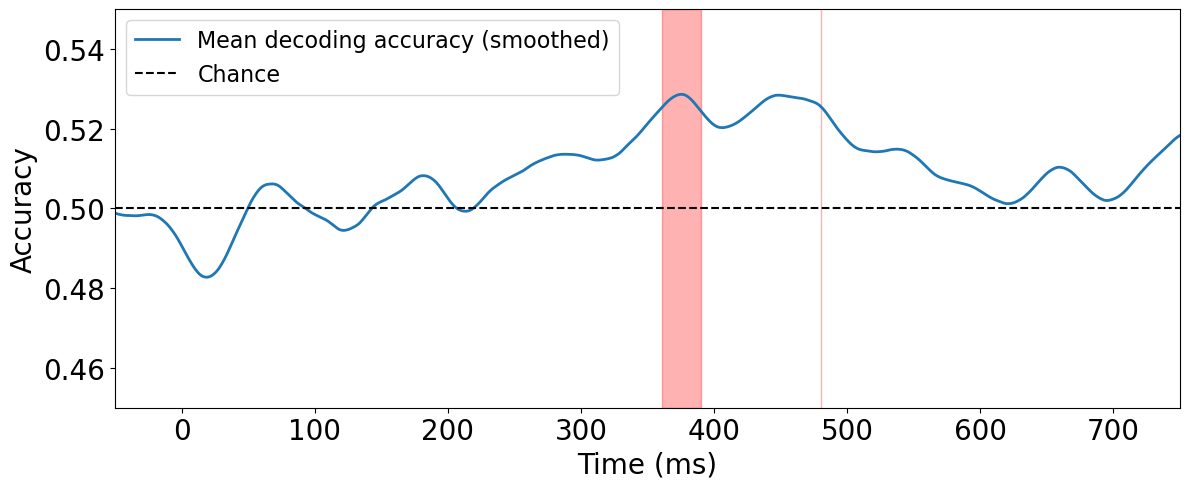

In [9]:
# -------------------------------------------------------
# VOT decoding: steps from target (per participant)
# -------------------------------------------------------

for ptp_id in tqdm(included):
    ptp_results_path = root_dir / f'{ptp_id}_VOTresults.p'

    if os.path.exists(ptp_results_path):
        print(f'{ptp_id} already done. Skipping')
        continue

    print(f'--- {ptp_id} ---')

    epochs = mne.read_epochs(epochs_path_template.format(ptp_id), preload=True, verbose=False)
    epochs.resample(1000, npad="auto")

    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs = epochs[epochs.metadata["vot-stepsfromtarget"].isin([1, 5])]
    epochs = epochs.copy().pick(['Pz', 'P3', 'P4'])

    X = epochs.get_data()
    y = epochs.metadata['vot-stepsfromtarget'].values

    scores, model, coeffs = temporal_decoding(X, y, cv=cv, n_jobs=n_jobs, mdl=mdl, scoring='accuracy', verbose=False)

    with open(ptp_results_path, 'wb') as f:
        pickle.dump({'scores': scores, 'coeffs': coeffs}, f)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(epochs.times, scores)
    ax.axhline(1 / len(np.unique(y)), color='k', linestyle='--', label='chance')
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Participant {ptp_id}: VOT decoding (task-relevant)")
    ax.legend()

    fig.savefig(root_dir / f'{ptp_id}_VOTscores.png', bbox_inches='tight')
    plt.close()


# -------------------------------------------------------
# VOT decoding: group-level statistics (Oleson et al., 2017)
# -------------------------------------------------------

result_files = [
    f for f in sorted(root_dir.glob('*_VOTresults.p'))
    if f.stem.split('_')[0] not in excluded
]

all_scores = []
for res_path in result_files:
    with open(res_path, 'rb') as f:
        subj_res = pickle.load(f)
    if subj_res.get('scores') is not None and len(subj_res['scores']) > 0:
        all_scores.append(subj_res['scores'])

if not all_scores:
    raise ValueError("No valid participant score files found.")

all_scores = np.array(all_scores)  # (n_subjects, n_times)

tmin, tmax = -0.1, 0.8
sfreq = 1000
times = np.linspace(tmin, tmax, all_scores.shape[1])
chance_level = 0.5

res = oleson_significance(
    all_scores, times,
    chance_level=chance_level,
    smoothing_ms=50,
    bin_ms=10,
    sfreq=sfreq,
    alpha=0.05,
    alternative='greater',
)

print(f"Lag-1 autocorrelation (rho): {res['rho']:.3f}")
print(f"Effective independent tests: {res['n_eff']:.2f}")
print(f"Corrected alpha: {res['alpha_corrected']:.5f}")

sig_windows = contiguous_windows(res['times_eval'], res['sig_mask'])
print("\nSignificant windows:")
if not sig_windows:
    print("  none")
for s, e in sig_windows:
    print(f"  {s*1000:.0f} – {e*1000:.0f} ms")

# === Plot ===
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(times * 1000, np.mean(res['smoothed'], axis=0), lw=2, label='Mean decoding accuracy (smoothed)')
ax.axhline(chance_level, linestyle='--', color='k', label='Chance')

for s, e in sig_windows:
    ax.axvspan(s * 1000, e * 1000, color='red', alpha=0.3)

ax.set_xlabel("Time (ms)", fontsize=20)
ax.set_ylabel("Accuracy", fontsize=20)
ax.set_ylim(.450, .550)
ax.set_xlim(-50, 750)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(fontsize=16)

plt.tight_layout()
save_path = figures_folder / "VOT_decoding_oleson.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {save_path.name}")
plt.show()

100%|██████████| 30/30 [00:00<00:00, 11885.25it/s]

105 already done. Skipping
106 already done. Skipping
107 already done. Skipping
110 already done. Skipping
111 already done. Skipping
112 already done. Skipping
113 already done. Skipping
116 already done. Skipping
120 already done. Skipping
123 already done. Skipping
124 already done. Skipping
125 already done. Skipping
127 already done. Skipping
128 already done. Skipping
129 already done. Skipping
130 already done. Skipping
131 already done. Skipping
132 already done. Skipping
134 already done. Skipping
135 already done. Skipping
136 already done. Skipping
137 already done. Skipping
139 already done. Skipping
140 already done. Skipping
141 already done. Skipping
142 already done. Skipping
143 already done. Skipping
145 already done. Skipping
146 already done. Skipping
147 already done. Skipping
Lag-1 autocorrelation (rho): 0.233
Effective independent tests: 56.03
Corrected alpha: 0.00089

Significant windows:
  401 – 421 ms
Figure saved: F0_decoding_oleson.png


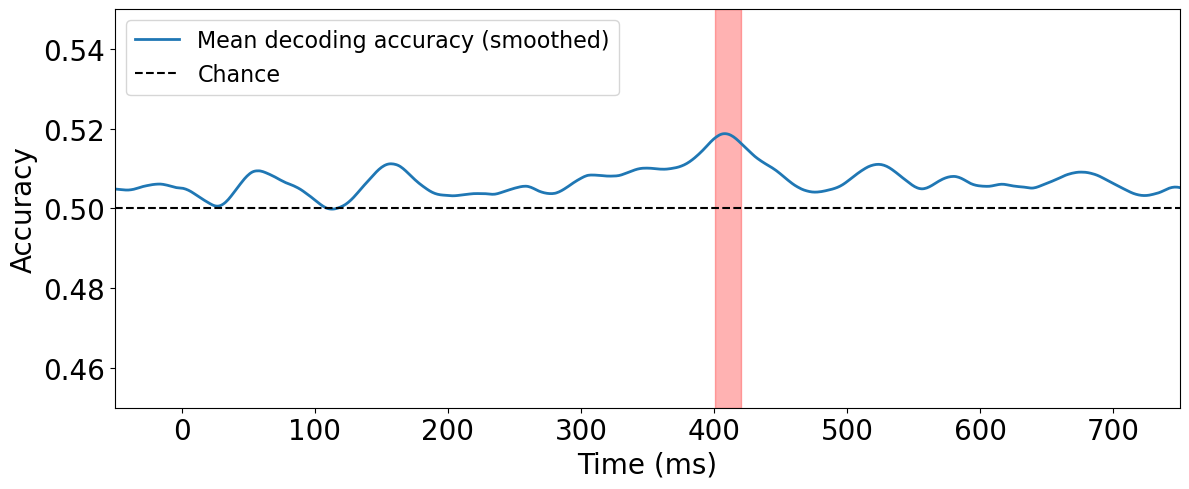

In [10]:
# -------------------------------------------------------
# F0 decoding: steps from target (per participant)
# -------------------------------------------------------

for ptp_id in tqdm(included):
    ptp_results_path = root_dir / f'{ptp_id}_F0results.p'

    if os.path.exists(ptp_results_path):
        print(f'{ptp_id} already done. Skipping')
        continue

    print(f'--- {ptp_id} ---')

    epochs = mne.read_epochs(epochs_path_template.format(ptp_id), preload=True, verbose=False)
    epochs.resample(1000, npad="auto")

    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs = epochs[epochs.metadata["f0-stepsfromtarget"].isin([1, 5])]
    epochs = epochs.copy().pick(['Pz', 'P3', 'P4'])

    X = epochs.get_data()
    y = epochs.metadata['f0-stepsfromtarget'].values

    scores, model, coeffs = temporal_decoding(X, y, cv=cv, n_jobs=n_jobs, mdl=mdl, scoring='accuracy', verbose=False)

    with open(ptp_results_path, 'wb') as f:
        pickle.dump({'scores': scores, 'coeffs': coeffs}, f)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(epochs.times, scores)
    ax.axhline(1 / len(np.unique(y)), color='k', linestyle='--', label='chance')
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Accuracy")
    ax.set_title(f"Participant {ptp_id}: F0 decoding (task-relevant)")
    ax.legend()

    fig.savefig(root_dir / f'{ptp_id}_F0scores.png', bbox_inches='tight')
    plt.close()


# -------------------------------------------------------
# F0 decoding: group-level statistics (Oleson et al., 2017)
# -------------------------------------------------------

result_files = [
    f for f in sorted(root_dir.glob('*_F0results.p'))
    if f.stem.split('_')[0] not in excluded
]

all_scores = []
for res_path in result_files:
    with open(res_path, 'rb') as f:
        subj_res = pickle.load(f)
    if subj_res.get('scores') is not None and len(subj_res['scores']) > 0:
        all_scores.append(subj_res['scores'])

if not all_scores:
    raise ValueError("No valid participant score files found.")

all_scores = np.array(all_scores)

tmin, tmax = -0.1, 0.8
sfreq = 1000
times = np.linspace(tmin, tmax, all_scores.shape[1])
chance_level = 0.5

res = oleson_significance(
    all_scores, times,
    chance_level=chance_level,
    smoothing_ms=50,
    bin_ms=10,
    sfreq=sfreq,
    alpha=0.05,
    alternative='greater',
)

print(f"Lag-1 autocorrelation (rho): {res['rho']:.3f}")
print(f"Effective independent tests: {res['n_eff']:.2f}")
print(f"Corrected alpha: {res['alpha_corrected']:.5f}")

sig_windows = contiguous_windows(res['times_eval'], res['sig_mask'])
print("\nSignificant windows:")
if not sig_windows:
    print("  none")
for s, e in sig_windows:
    print(f"  {s*1000:.0f} – {e*1000:.0f} ms")

# === Plot ===
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(times * 1000, np.mean(res['smoothed'], axis=0), lw=2, label='Mean decoding accuracy (smoothed)')
ax.axhline(chance_level, linestyle='--', color='k', label='Chance')

for s, e in sig_windows:
    ax.axvspan(s * 1000, e * 1000, color='red', alpha=0.3)

ax.set_xlabel("Time (ms)", fontsize=20)
ax.set_ylabel("Accuracy", fontsize=20)
ax.set_ylim(.450, .550)
ax.set_xlim(-50, 750)
ax.tick_params(axis='both', which='major', labelsize=20)
ax.legend(fontsize=16)

plt.tight_layout()
save_path = figures_folder / "F0_decoding_oleson.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"Figure saved: {save_path.name}")
plt.show()

In [ ]:
# ============================================================
# Analysis 3: Acoustic cue weights
# ============================================================


=== Sphericity (Mauchly) ===
SpherResults(spher=True, W=np.float64(0.8289754855307049), chi2=np.float64(5.1997101673968995), dof=5, pval=np.float64(0.3922568620388153))

=== One-way rm-ANOVA (auto Greenhouse-Geisser if needed) ===
   Source         SS  DF        MS        F   p_unc      np2      eps
condition  43.513528   3 14.504509 8.002639 0.00009 0.216272 0.882586
    Error 157.684523  87  1.812466      NaN     NaN      NaN      NaN

=== Planned one-tailed paired t-tests ===
           Comparison     t   dz p (raw) p (Holm)  Sig (Holm)
Optimal vs Strong VOT 1.429 0.26  0.0818   0.0818       False
 Optimal vs Strong F0 2.607 0.48  0.0071   0.0214        True
Strong VOT vs Neither 3.195 0.58  0.0017   0.0067        True
 Strong F0 vs Neither 2.280 0.42  0.0151   0.0302        True

Figure saved: cue_weights_anova.png


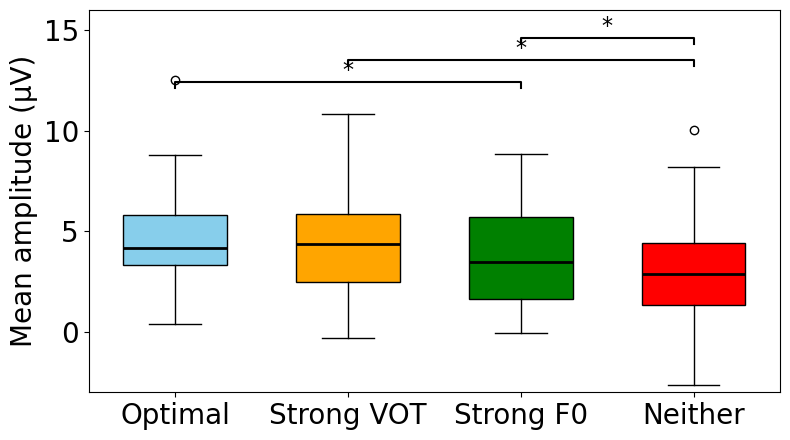

In [11]:
# -------------------------------------------------------
# Cue weights: repeated-measures ANOVA + planned t-tests
# -------------------------------------------------------

picks = ["Pz", "P3", "P4"]
tmin, tmax = 0.3, 0.6
epochs_folder = Path(os.getcwd()) / "epochs/"
epoch_files = list(epochs_folder.glob("*-epo.fif"))
figures_folder = Path(os.getcwd()) / "figures/"
figures_folder.mkdir(parents=True, exist_ok=True)

conditions = {
    "optimal":    lambda row: ((row["VOT"] == 1) & (row["F0"] == 1)) |
                              ((row["VOT"] == 5) & (row["F0"] == 5)),
    "strong VOT": {"VOT_step": 2, "F0_step": 0},
    "strong F0":  {"VOT_step": 0, "F0_step": 1},
    "neither":    {"VOT_step": 0, "F0_step": 0},
}

data_dict = {cond: [] for cond in conditions}
participants = []

for epoch_file in epoch_files:
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    if participant_id not in included:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)
    epochs.pick(picks)
    epochs = epochs[epochs.metadata["task-relevant"] == "yes"]
    epochs.crop(tmin=tmin, tmax=tmax)

    participant_data = {}
    skip_participant = False
    for cond_name, cond_vals in conditions.items():
        if callable(cond_vals):
            cond_epochs = epochs[epochs.metadata.apply(cond_vals, axis=1)]
        else:
            cond_epochs = epochs[
                (epochs.metadata["VOT_step"] == cond_vals["VOT_step"]) &
                (epochs.metadata["F0_step"] == cond_vals["F0_step"])
            ]
        if len(cond_epochs) == 0:
            skip_participant = True
            break
        participant_data[cond_name] = cond_epochs.average().data.mean() * 1e6

    if skip_participant:
        print(f"Skipping {participant_id}: missing one or more conditions")
        continue

    for cond_name in conditions:
        data_dict[cond_name].append(participant_data[cond_name])
    participants.append(participant_id)

# === LONG-FORMAT DATAFRAME ===
cond_order = ["optimal", "strong VOT", "strong F0", "neither"]
df_long = pd.DataFrame({
    "participant": np.tile(participants, len(cond_order)),
    "condition":   np.repeat(cond_order, len(participants)),
    "amplitude":   np.concatenate([data_dict[c] for c in cond_order]),
})

# === SPHERICITY CHECK ===
print("\n=== Sphericity (Mauchly) ===")
print(pg.sphericity(df_long, dv="amplitude", within="condition", subject="participant"))

# === ONE-WAY REPEATED-MEASURES ANOVA ===
print("\n=== One-way rm-ANOVA (auto Greenhouse-Geisser if needed) ===")
aov = pg.rm_anova(
    data=df_long,
    dv="amplitude",
    within="condition",
    subject="participant",
    correction="auto",
    detailed=True,
    effsize="np2",
)
print(aov.to_string(index=False))

# === PLANNED ONE-TAILED PAIRED T-TESTS ===
optimal    = np.array(data_dict["optimal"])
strong_vot = np.array(data_dict["strong VOT"])
strong_f0  = np.array(data_dict["strong F0"])
neither    = np.array(data_dict["neither"])

planned_tests = [
    ("Optimal vs Strong VOT", optimal,    strong_vot),
    ("Optimal vs Strong F0",  optimal,    strong_f0),
    ("Strong VOT vs Neither", strong_vot, neither),
    ("Strong F0 vs Neither",  strong_f0,  neither),
]

tvals, raw_pvals = [], []
for _, a, b in planned_tests:
    t, p = ttest_rel(a, b, alternative="greater")
    tvals.append(t)
    raw_pvals.append(p)

reject, p_holm, _, _ = multipletests(raw_pvals, alpha=0.05, method="holm")

def cohens_dz(a, b):
    diff = np.array(a) - np.array(b)
    return diff.mean() / diff.std(ddof=1)

dz_vals = [cohens_dz(a, b) for _, a, b in planned_tests]

results_df = pd.DataFrame({
    "Comparison": [t[0] for t in planned_tests],
    "t":          [f"{v:.3f}" for v in tvals],
    "dz":         [f"{v:.2f}"  for v in dz_vals],
    "p (raw)":    [f"{v:.4f}" for v in raw_pvals],
    "p (Holm)":   [f"{v:.4f}" for v in p_holm],
    "Sig (Holm)": reject,
})
print("\n=== Planned one-tailed paired t-tests ===")
print(results_df.to_string(index=False))

# === PLOT ===
fig, ax = plt.subplots(figsize=(8, 4.5))
x_positions = np.arange(1, len(cond_order) + 1)
colors = ["skyblue", "orange", "green", "red"]

boxplots = ax.boxplot(
    [data_dict[c] for c in cond_order],
    positions=x_positions,
    widths=0.6,
    patch_artist=True,
    boxprops=dict(color="black"),
    medianprops=dict(color="black", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
)
for patch, color in zip(boxplots["boxes"], colors):
    patch.set_facecolor(color)

ax.set_xticks(x_positions)
ax.set_xticklabels(["Optimal", "Strong VOT", "Strong F0", "Neither"], fontsize=20)
ax.set_ylabel("Mean amplitude (µV)", fontsize=20)
ax.tick_params(axis="both", which="major", labelsize=20)
ax.set_ylim(-3, 16)

def add_sig_line(ax, x1, x2, y, h, pval, fontsize=16):
    if pval < 0.05:
        ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], color="black", linewidth=1.5)
        ax.text((x1 + x2) / 2, y + h, "*", ha="center", va="bottom", fontsize=fontsize)

sig_pairs = [
    (1, 2, p_holm[0]),
    (1, 3, p_holm[1]),
    (2, 4, p_holm[2]),
    (3, 4, p_holm[3]),
]

ymax, step = 11, 11 * 0.1
y = ymax
for x1, x2, pval in sig_pairs:
    add_sig_line(ax, x1, x2, y, step * 0.3, pval)
    y += step

plt.tight_layout()
save_path = figures_folder / "cue_weights_anova.png"
fig.savefig(save_path, dpi=300, bbox_inches="tight")
print(f"\nFigure saved: {save_path.name}")
plt.show()

# ============================================================
# Supplementary analyses
# ============================================================

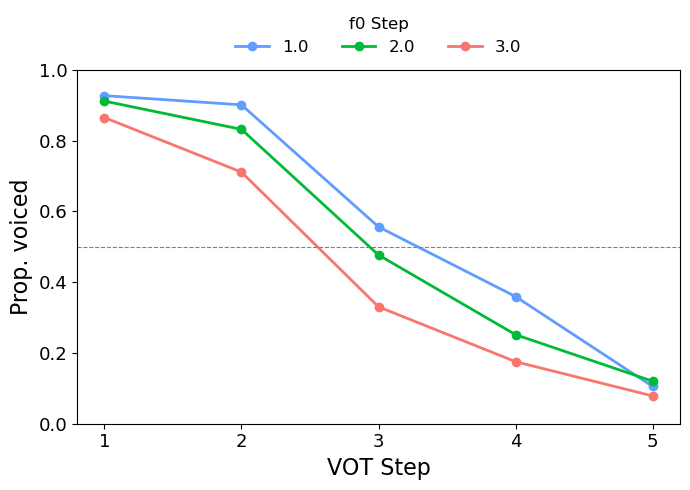

In [12]:
# ---------------------------------------------------------
# Figure S1: categorization function (task-relevant trials, included participants)
# MEASURE = "voiced":    proportion of voiced judgments by the stimulus's VOT and f0 step
#                        (VOT 1 = 0 ms, f0 1 = 250 Hz)
# MEASURE = "nontarget": proportion of "not the target" responses by steps on a
#                        target-relative scale (1 = farthest from the target); this
#                        reproduces the current Figure S1
# ---------------------------------------------------------
MEASURE = "voiced"

behavior_folder = Path(os.getcwd()) / "behavior"
figures_folder = Path(os.getcwd()) / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

data = pd.concat([pd.read_csv(f, dtype={"participant": str})
                  for f in sorted(behavior_folder.glob("*_ob.csv"))], ignore_index=True)

# Stimulus steps from the file name, e.g. Stimuli_channel3/dt2_5.wav -> continuum dt, VOT 2, f0 5
steps = data["audio_clip"].str.extract(r"(bp|dt)(\d)_(\d)\.wav")
data["continuum"] = steps[0]
data["VOT"] = pd.to_numeric(steps[1])
data["F0"] = pd.to_numeric(steps[2]).map({1: 1, 3: 2, 5: 3})        # f0 steps 1-3

# Included participants, task-relevant trials, valid responses only
voiced_target = data["target"].isin(["dear", "beach"])
task_relevant = (((data["continuum"] == "bp") & data["target"].isin(["beach", "peach"])) |
                 ((data["continuum"] == "dt") & data["target"].isin(["dear", "tear"])))
keep = (data["participant"].isin(included) & task_relevant &
        data["oddball_response.keys"].isin(["m", "n"]))
data, voiced_target = data[keep], voiced_target[keep]
said_target = data["oddball_response.keys"] == "n"

if MEASURE == "voiced":
    data["y"] = np.where(voiced_target, said_target, ~said_target)    # voiced judgment
    data["x"], data["line"] = data["VOT"], data["F0"]
    y_label, file_name = "Prop. voiced", "behavior_categorization_prop.png"
else:
    data["y"] = ~said_target                                            # "not the target"
    data["x"] = np.where(voiced_target, 6 - data["VOT"], data["VOT"])
    data["line"] = np.where(voiced_target, 4 - data["F0"], data["F0"])
    y_label, file_name = "Prop. non-target responses", "behavior_categorization_nontarget.png"

summary = data.groupby(["line", "x"])["y"].mean().reset_index()

# Plot
colors = {1: "#619CFF", 2: "#00BA38", 3: "#F8766D"}
fig, ax = plt.subplots(figsize=(7, 5))
for f0_step, g in summary.groupby("line"):
    ax.plot(g["x"], g["y"], color=colors[f0_step], linewidth=2, marker="o", label=str(f0_step))
ax.axhline(0.5, linestyle="--", color="gray", linewidth=0.8)
ax.set_xticks(range(1, 6))
ax.set_ylim(0, 1)
ax.set_xlabel("VOT Step", fontsize=16)
ax.set_ylabel(y_label, fontsize=16)
ax.tick_params(labelsize=13)
ax.legend(title="f0 Step", ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0),
          frameon=False, fontsize=12, title_fontsize=12)
plt.tight_layout()
fig.savefig(figures_folder / file_name, dpi=300, bbox_inches="tight")
plt.show()

Participants: 30
Trials (task-relevant, 'n' responses): 9486
Participants contributing per VOT step: {0: 30, 1: 30, 2: 30, 3: 30, 4: 29}
Figure saved: VOT_steps_nresponses.png


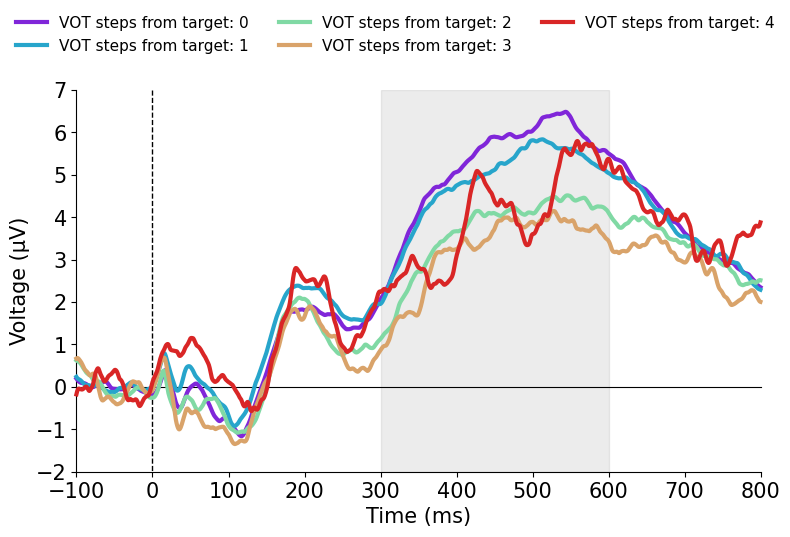

Figure saved: f0_steps_nresponses.png


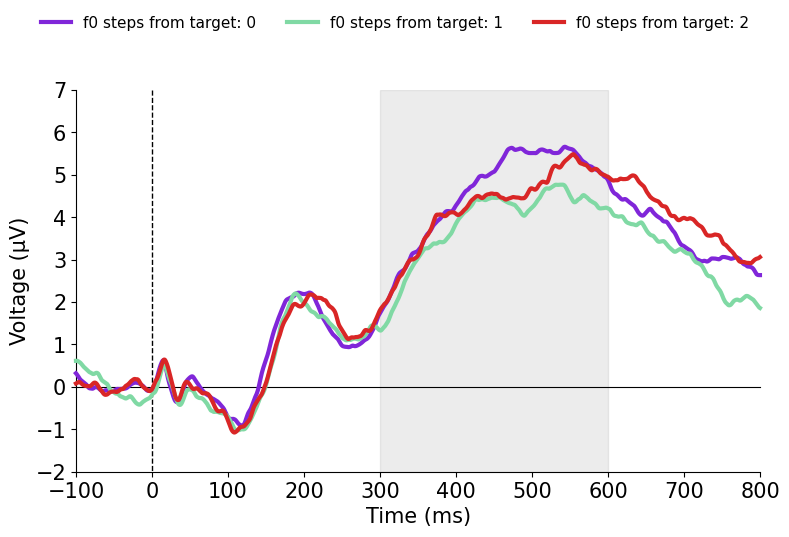

          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: mean_voltage
No. Observations: 9486    Method:             REML        
No. Groups:       30      Scale:              119.4446    
Min. group size:  245     Log-Likelihood:     -36189.1542 
Max. group size:  418     Converged:          Yes         
Mean group size:  316.2                                   
-----------------------------------------------------------
            Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
-----------------------------------------------------------
Intercept    5.500     0.511  10.758  0.000   4.498   6.502
vot_steps   -0.544     0.101  -5.370  0.000  -0.743  -0.346
f0_steps    -0.308     0.139  -2.211  0.027  -0.580  -0.035
Group Var    6.438     0.164                               



In [13]:
# =============================================================
# Analysis 1: P3 amplitude by VOT and f0 steps from target
# Task-relevant trials with an on-target ("n") response only
#
# P3 = mean voltage at Pz, P3, P4 in the 300-600 ms window.
# Steps from target are coded so that 0 = the target:
#   VOT 0-4 (metadata 1-5), f0 0-2 (metadata 1/3/5).
# Requires `included` and `clean_id` from the exclusion-criteria cell.
# =============================================================

import os
from collections import OrderedDict
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from statsmodels.formula.api import mixedlm

mne.set_log_level("WARNING")

# --- Settings ------------------------------------------------
epochs_folder  = Path(os.getcwd()) / "epochs"
figures_folder = Path(os.getcwd()) / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

PICKS   = ["Pz", "P3", "P4"]
P3_WIN  = (0.3, 0.6)                      # seconds
F0_STEP = {1: 0, 3: 1, 5: 2}              # metadata code -> steps from target
VOT_STEP = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4}

# --- Load data: trial-level P3 and participant-level ERPs ----
trial_tables = []
erps = []                                 # one evoked per participant x VOT x f0 x target voicing

for epoch_file in sorted(epochs_folder.glob("*-epo.fif")):
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    if participant_id not in included:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)
    epochs = epochs[(epochs.metadata["task-relevant"] == "yes") &
                    (epochs.metadata["oddball_response.keys"] == "n")]

    md = epochs.metadata.reset_index(drop=True).copy()
    md["participant"]  = participant_id
    md["vot_steps"]    = md["vot-stepsfromtarget"].astype(int).map(VOT_STEP)
    md["f0_steps"]     = md["f0-stepsfromtarget"].astype(int).map(F0_STEP)
    md["target_voice"] = np.where(md["target"].isin(["dear", "beach"]), "voiced", "voiceless")

    # Single-trial P3 amplitude (µV)
    p3 = epochs.copy().pick(PICKS).crop(*P3_WIN).get_data().mean(axis=(1, 2)) * 1e6
    md["mean_voltage"] = p3
    trial_tables.append(md[["participant", "vot_steps", "f0_steps", "target_voice", "Continuum", "mean_voltage"]])

    # Participant-level ERPs for the figures
    for (v, f, voice), idx in md.groupby(["vot_steps", "f0_steps", "target_voice"]).indices.items():
        evk = epochs[idx].average()
        erps.append({"participant": participant_id, "vot_steps": v, "f0_steps": f, "evoked": evk})

df_lmm = pd.concat(trial_tables, ignore_index=True)
erps = pd.DataFrame(erps)

print(f"Participants: {df_lmm['participant'].nunique()}")
print(f"Trials (task-relevant, 'n' responses): {len(df_lmm)}")
print("Participants contributing per VOT step:",
      df_lmm.groupby("vot_steps")["participant"].nunique().to_dict())

# --- Figures: P3 by steps from target ------------------------
def muted_rainbow(n):
    cs = plt.cm.rainbow(np.linspace(0, 1, n))
    return [(c[0]*0.7+0.15, c[1]*0.7+0.15, c[2]*0.7+0.15, c[3]) for c in cs]

def plot_steps_from_target(cue, column, save_name):
    groups = OrderedDict(
        (f"{cue} steps from target: {step}", erps.loc[erps[column] == step, "evoked"].tolist())
        for step in sorted(erps[column].unique())
    )

    fig, ax = plt.subplots(figsize=(8, 5))
    mne.viz.plot_compare_evokeds(groups, combine="mean", picks=PICKS, title="", axes=ax,
                                 ylim=dict(eeg=[-2, 7]), legend=False, time_unit="ms",
                                 ci=False, show=False)
    while len(fig.axes) > 1:              # remove extra axes added by MNE
        fig.axes[1].remove()

    colors = muted_rainbow(len(groups))
    for line, col in zip(ax.lines, colors):
        line.set_color(col); line.set_linewidth(3)
    if ax.get_legend() is not None:
        ax.get_legend().remove()

    ax.axvspan(P3_WIN[0] * 1000, P3_WIN[1] * 1000, color="grey", alpha=0.15, zorder=0)
    ax.set_xlabel("Time (ms)", fontsize=15)
    ax.set_ylabel("Voltage (µV)", fontsize=15)
    ax.tick_params(axis="both", labelsize=15)
    ax.set_xticks(range(-100, 801, 100))
    ax.spines["bottom"].set_bounds(-100, 800)
    ax.set_xlim(-100, 800)

    handles = [mlines.Line2D([0], [0], color=c, lw=3, label=lab) for c, lab in zip(colors, groups)]
    fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08),
               frameon=False, fontsize=11)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(figures_folder / save_name, dpi=300, bbox_inches="tight", pad_inches=0.1)
    print(f"Figure saved: {save_name}")
    plt.show()

plot_steps_from_target("VOT", "vot_steps", "VOT_steps_nresponses.png")
plot_steps_from_target("f0",  "f0_steps",  "f0_steps_nresponses.png")

# --- Linear mixed-effects model ------------------------------
# Additive model with a by-participant random intercept
model = mixedlm("mean_voltage ~ vot_steps + f0_steps", df_lmm, groups=df_lmm["participant"]).fit()
print(model.summary())

Participants: 30 | task-relevant trials: 17300

Linear effect of steps from target on P3 amplitude within each slice:
               effect                        at  B (µV/step)    SE      z     p  trials  participants  p (Holm)
VOT steps from target  f0 steps from target = 0       -0.572 0.100 -5.751 0.000    5792            30     0.000
VOT steps from target  f0 steps from target = 1       -0.301 0.103 -2.921 0.003    5754            30     0.021
VOT steps from target  f0 steps from target = 2       -0.386 0.101 -3.808 0.000    5754            30     0.001
 f0 steps from target VOT steps from target = 0       -0.402 0.231 -1.743 0.081    3472            30     0.389
 f0 steps from target VOT steps from target = 1       -0.401 0.227 -1.764 0.078    3452            30     0.389
 f0 steps from target VOT steps from target = 2       -0.014 0.232 -0.058 0.953    3457            30     1.000
 f0 steps from target VOT steps from target = 3       -0.343 0.216 -1.585 0.113    3465           

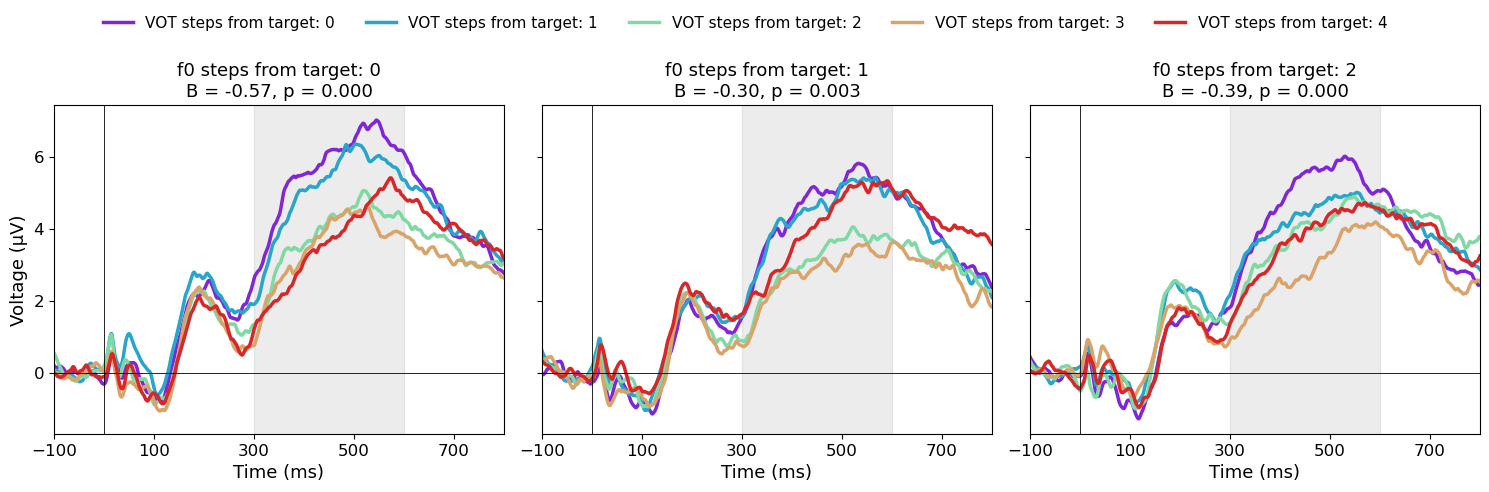

Figure saved: f0_atvot.png


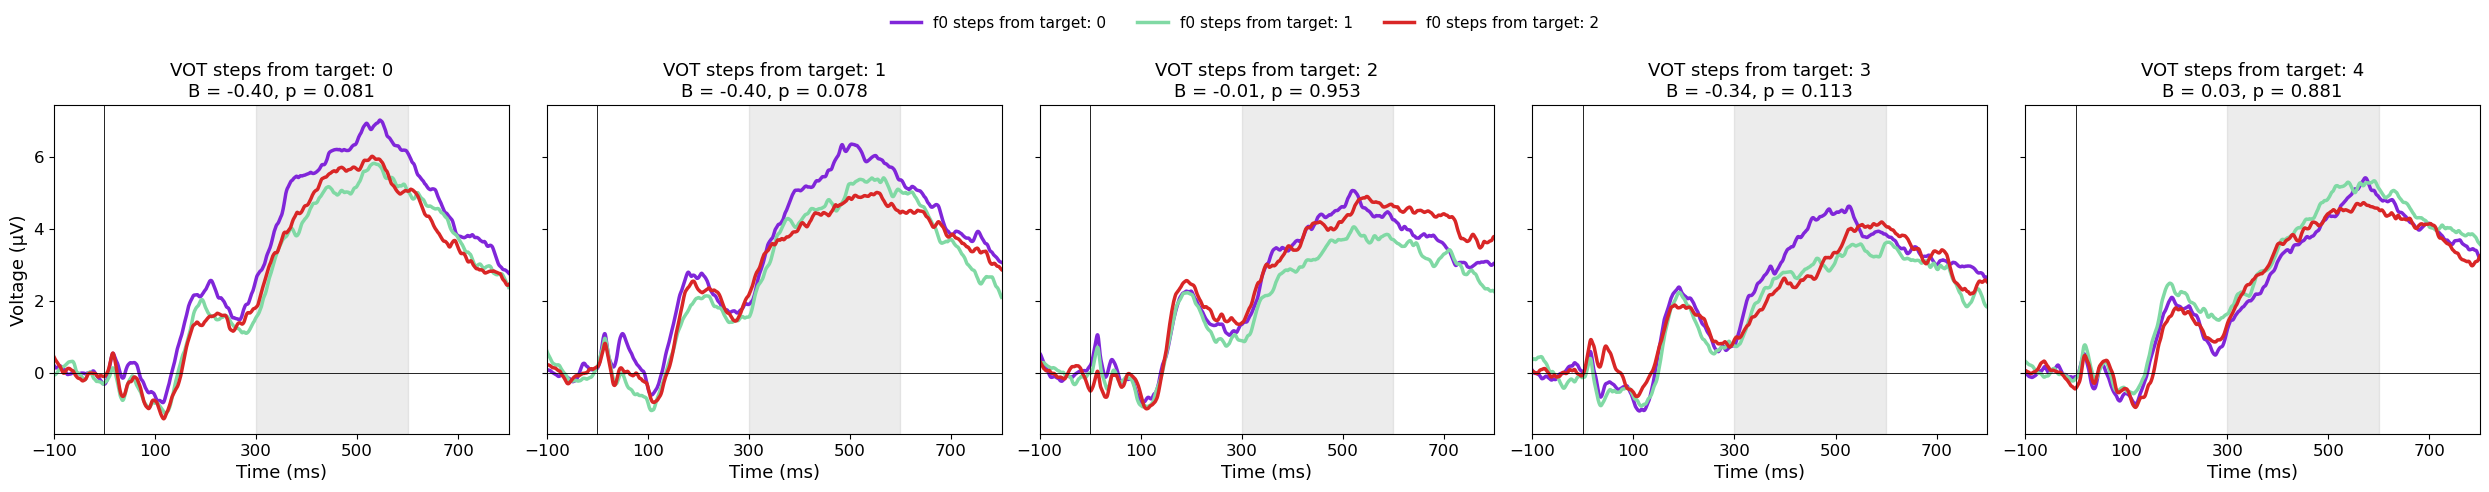

In [14]:
# =============================================================
# Simple effects of VOT and f0 on P3 amplitude
# Task-relevant trials, all responses
#
# For each level of one cue, tests the linear effect of the other cue's
# steps from target on P3 amplitude (8 slices: VOT at each of 3 f0 levels,
# f0 at each of 5 VOT levels), and plots the waveforms for each slice (Figure S3).
#
# P3 = mean voltage at Pz, P3, P4 in the 300-600 ms window.
# Steps from target are coded so that 0 = the target:
#   VOT 0-4 (metadata 1-5), f0 0-2 (metadata 1/3/5).
# Requires `included` and `clean_id` from the exclusion-criteria cell.
# =============================================================
import os
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from statsmodels.formula.api import mixedlm
from statsmodels.stats.multitest import multipletests

mne.set_log_level("WARNING")

# --- Settings ------------------------------------------------
epochs_folder  = Path(os.getcwd()) / "epochs"
figures_folder = Path(os.getcwd()) / "figures"
figures_folder.mkdir(parents=True, exist_ok=True)

PICKS    = ["Pz", "P3", "P4"]
P3_WIN   = (0.3, 0.6)                     # seconds
VOT_STEP = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4}  # metadata code -> steps from target
F0_STEP  = {1: 0, 3: 1, 5: 2}
CUES     = {"VOT": "vot_steps", "f0": "f0_steps"}

def muted_rainbow(n):
    cs = plt.cm.rainbow(np.linspace(0, 1, n))
    return [(c[0]*0.7+0.15, c[1]*0.7+0.15, c[2]*0.7+0.15, c[3]) for c in cs]

# --- Load data: trial-level P3 and participant-level waveforms ----
trial_tables, wave_rows = [], []

for epoch_file in sorted(epochs_folder.glob("*-epo.fif")):
    participant_id = clean_id(epoch_file.stem.split("-epo")[0])
    if participant_id not in included:
        continue

    epochs = mne.read_epochs(epoch_file, preload=True, verbose=False)
    epochs = epochs[epochs.metadata["task-relevant"] == "yes"].pick(PICKS)

    md = epochs.metadata.reset_index(drop=True)
    data = epochs.get_data().mean(axis=1) * 1e6          # trials x time, µV (mean over electrodes)
    times_ms = epochs.times * 1000
    in_win = (epochs.times >= P3_WIN[0]) & (epochs.times <= P3_WIN[1])

    trials = pd.DataFrame({
        "participant":  participant_id,
        "vot_steps":    md["vot-stepsfromtarget"].astype(int).map(VOT_STEP).values,
        "f0_steps":     md["f0-stepsfromtarget"].astype(int).map(F0_STEP).values,
        "target_voice": np.where(md["target"].isin(["dear", "beach"]), "voiced", "voiceless"),
        "mean_voltage": data[:, in_win].mean(axis=1),
    })
    trial_tables.append(trials)

    # Participant-level waveform for each stimulus cell (target voicings averaged separately)
    for (v, f, voice), idx in trials.groupby(["vot_steps", "f0_steps", "target_voice"]).indices.items():
        wave_rows.append({"participant": participant_id, "vot_steps": v, "f0_steps": f,
                          "wave": data[idx].mean(axis=0)})

df = pd.concat(trial_tables, ignore_index=True)
waves = pd.DataFrame(wave_rows)
print(f"Participants: {df['participant'].nunique()} | task-relevant trials: {len(df)}")

# --- Statistics: linear effect within each slice ------------------
rows = []
for cue, x in CUES.items():
    other_cue, other = [(c, col) for c, col in CUES.items() if c != cue][0]
    for level in sorted(df[other].unique()):
        sub = df[df[other] == level]
        m = mixedlm(f"mean_voltage ~ {x}", sub, groups=sub["participant"]).fit()
        rows.append({"effect": f"{cue} steps from target",
                     "at": f"{other_cue} steps from target = {level}",
                     "cue": cue, "level": level,
                     "B (µV/step)": m.fe_params[x], "SE": m.bse[x], "z": m.tvalues[x],
                     "p": m.pvalues[x], "trials": len(sub),
                     "participants": sub["participant"].nunique()})
simple = pd.DataFrame(rows)
simple["p (Holm)"] = multipletests(simple["p"], method="holm")[1]

print("\nLinear effect of steps from target on P3 amplitude within each slice:")
print(simple.drop(columns=["cue", "level"]).round(3).to_string(index=False))
simple.drop(columns=["cue", "level"]).to_csv(figures_folder / "simple_effects_allresponses.csv", index=False)  # Table S2

def stat_label(cue, level):
    r = simple[(simple["cue"] == cue) & (simple["level"] == level)].iloc[0]
    return f"B = {r['B (µV/step)']:.2f}, p = {r['p']:.3f}"

# --- Figure S3: waveforms for each slice ---------------------------
# vot_atf0.png: VOT effect at each f0 level (top panel of Figure S3)
# f0_atvot.png: f0 effect at each VOT level (bottom panel of Figure S3)
SAVE_NAMES = {"VOT": "vot_atf0.png", "f0": "f0_atvot.png"}

for cue, x in CUES.items():
    other_cue, other = [(c, col) for c, col in CUES.items() if c != cue][0]
    other_levels, x_levels = sorted(waves[other].unique()), sorted(waves[x].unique())
    colors = muted_rainbow(len(x_levels))

    fig, axes = plt.subplots(1, len(other_levels), figsize=(5 * len(other_levels), 4.5), sharey=True)
    for ax, level in zip(axes, other_levels):
        for xl, col in zip(x_levels, colors):
            cell = waves[(waves[other] == level) & (waves[x] == xl)]
            # average target voicings within each participant, then across participants
            per_participant = cell.groupby("participant")["wave"].apply(lambda s: np.mean(np.stack(s), axis=0))
            ax.plot(times_ms, np.mean(np.stack(per_participant), axis=0), color=col, lw=2.5,
                    label=f"{cue} steps from target: {xl}")
        ax.axvspan(P3_WIN[0] * 1000, P3_WIN[1] * 1000, color="grey", alpha=0.15, zorder=0)
        ax.axhline(0, color="black", lw=0.6)
        ax.axvline(0, color="black", lw=0.6)
        ax.set_xlim(-100, 800)
        ax.set_xticks(range(-100, 801, 200))
        ax.set_title(f"{other_cue} steps from target: {level}\n{stat_label(cue, level)}", fontsize=13)
        ax.set_xlabel("Time (ms)", fontsize=13)
        ax.tick_params(axis="both", labelsize=12)
    axes[0].set_ylabel("Voltage (µV)", fontsize=13)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(labels),
               bbox_to_anchor=(0.5, 1.1), frameon=False, fontsize=11)
    plt.tight_layout()
    fig.savefig(figures_folder / SAVE_NAMES[cue], dpi=300, bbox_inches="tight", pad_inches=0.1)
    print(f"Figure saved: {SAVE_NAMES[cue]}")
    plt.show()

Participants analyzed: 30

=== PART 1: Descriptives ===
Gradience (log slope): median = 1.82, IQR = 1.27-2.03, range = 0.54-2.61
Cue use (theta, deg): median = 80.24, IQR = 76.83-83.99, range = 36.28-91.11
Fits at the slope ceiling (step-like): 19 of 60
Gradience vs cue use: Spearman rho = 0.34, p = 0.066

=== PART 2a: Heterogeneity (own value per listener vs one shared value) ===
Gradience (slope): chi2(58) = 219.0, p = 1.5e-20
Cue use (angle): chi2(58) = 289.2, p = 2e-32

=== PART 2b: Split-half reliability (odd vs even trials) ===
Gradience (slope): split-half rho = 0.23 (p = 0.218), Spearman-Brown corrected = 0.38
Cue use (angle): split-half rho = 0.36 (p = 0.053), Spearman-Brown corrected = 0.53
Gradience: consistency across continua rho = 0.05 (p = 0.798)
Cue use: consistency across continua rho = 0.14 (p = 0.465)

=== PART 3a: Listener-level P3 vs behaviour ===
Spearman correlations (Holm across 4):
      neural behaviour    rho     p  p_holm
   Amplitude gradience -0.076 0.690 

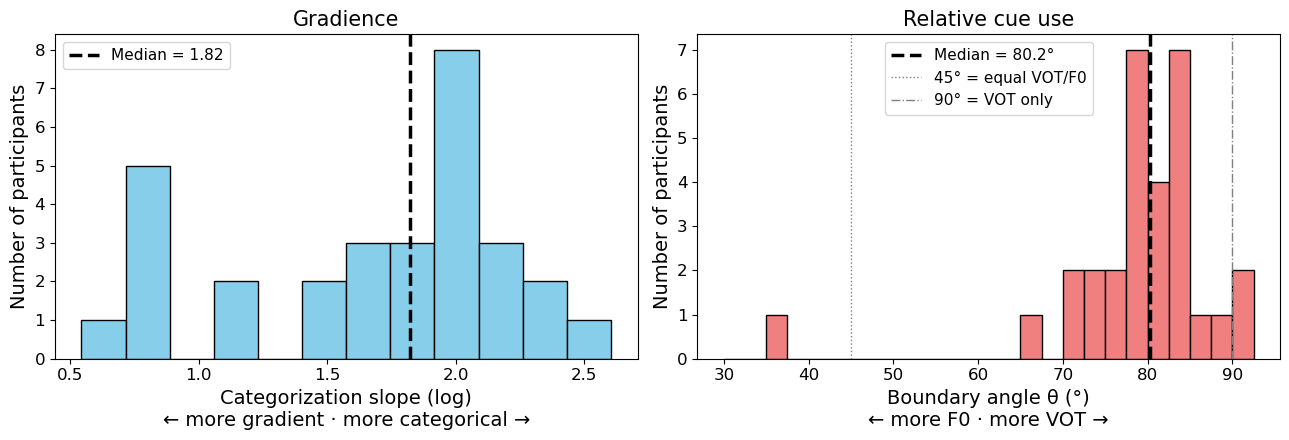

Figure saved: supp_p3_behavior_scatter.png


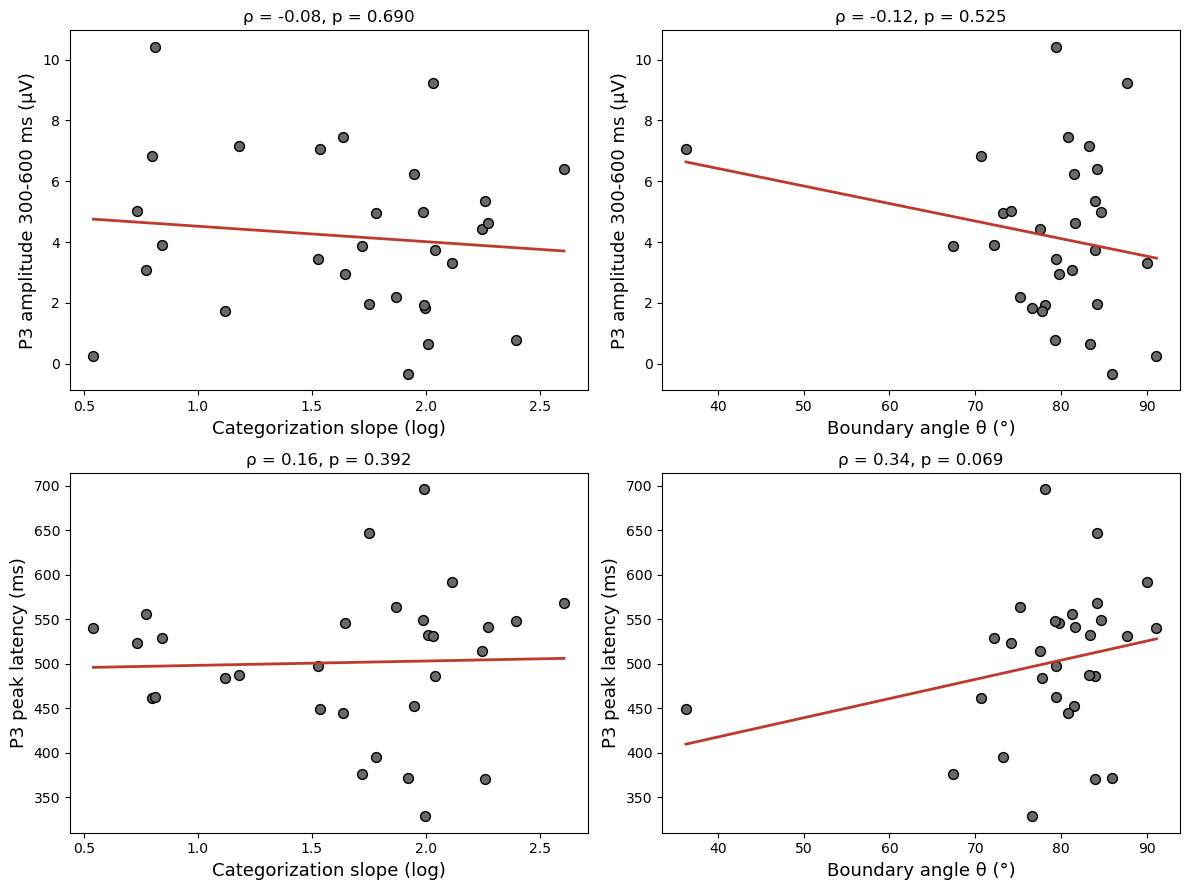

In [15]:
# =====================================================================
# INDIVIDUAL DIFFERENCES IN CATEGORIZATION AND THE P3
# Run directly after the exclusion-criteria cell (uses `included`, `epochs_folder`).
#
#   PART 1  Behaviour: gradience and relative cue use per listener
#           (rotated logistic; Kapnoula & McMurray, 2021)
#   PART 2  Behaviour stats: are the individual differences real?
#             - heterogeneity LRTs (own slope / own angle vs shared)
#             - split-half reliability (odd vs even trials)
#   PART 3  P3 (task-relevant, "n" responses, Pz/P3/P4):
#             amplitude 300-600 ms, peak latency 250-750 ms
#           Continuous analyses (primary):
#             - listener level: amplitude / latency ~ gradience + cue use
#             - trial level: distance from target x gradience / cue use
#   PART 4  Figures for Supplement S8, saved to FIG_DIR with the names used
#           in the supplement (\includegraphics):
#             supp_behavior_distributions.png  (Figure S4)
#             supp_p3_behavior_scatter.png     (Figure S5)
# =====================================================================
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import statsmodels.formula.api as smf
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import spearmanr, chi2
from statsmodels.stats.multitest import multipletests

mne.set_log_level("WARNING")
SLOPE_MAX = 15.0
P3_CHANS, P3_WIN, PEAK_WIN = ["Pz", "P3", "P4"], (0.30, 0.60), (0.25, 0.75)
FIG_DIR = Path(os.getcwd()) / "figures"      # copy these files into images/ in the LaTeX project
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Figure saved: {name}")

# =====================================================================
# PART 1. BEHAVIOUR: GRADIENCE AND RELATIVE CUE USE
# =====================================================================
rows = []
for f in sorted(epochs_folder.glob("*-epo.fif")):
    pid = f.stem.split("-epo")[0].replace("subj-", "")
    if pid not in included:
        continue
    md = mne.read_epochs(f, preload=False, verbose=False).metadata          # metadata only
    md = md[(md["task-relevant"] == "yes") & md["oddball_response.keys"].isin(["n", "m"])].copy()
    md["participant"] = pid
    rows.append(md)
beh_trials = pd.concat(rows, ignore_index=True)
print(f"Participants analyzed: {beh_trials['participant'].nunique()}")

# "n" = "this is the target" -> voicing judgement
voiceless_block = ~beh_trials["target"].isin(["dear", "beach"])
said_target = beh_trials["oddball_response.keys"] == "n"
beh_trials["resp_voiceless"] = np.where(voiceless_block, said_target, ~said_target).astype(int)
beh_trials["block"] = voiceless_block.astype(int)
beh_trials["v"] = beh_trials["VOT"].astype(float) - 3
beh_trials["f"] = beh_trials["F0"].astype(float) - 3

# p = b1 + (b2-b1) / (1 + exp(-s * (cos(phi)*VOT + sin(phi)*F0 - k - delta*block)))
#   s = slope (gradience), theta = 90 - phi (cue use), delta = block response bias
PNAMES = ["b1", "b2", "s", "phi", "k", "delta"]
BOUNDS = dict(b1=(0, .45), b2=(.55, 1), s=(.05, SLOPE_MAX), phi=(-np.pi / 4, 3 * np.pi / 4), k=(-4, 4), delta=(-4, 4))

def nll(p, d):
    b1, b2, s, phi, k, delta = p
    pr = b1 + (b2 - b1) / (1 + np.exp(-s * (np.cos(phi) * d["v"] + np.sin(phi) * d["f"] - k - delta * d["block"])))
    pr = np.clip(pr, 1e-6, 1 - 1e-6)
    return -np.sum(d["y"] * np.log(pr) + (1 - d["y"]) * np.log(1 - pr))

def fit(d, fixed=None, start=None):
    """ML fit; `fixed` = {param: value} holds parameters constant. Returns (params, nll)."""
    fixed = fixed or {}
    free = [n for n in PNAMES if n not in fixed]
    def full(x):
        p = dict(zip(free, x)); p.update(fixed)
        return [p[n] for n in PNAMES]
    starts = ([[start[PNAMES.index(n)] for n in free]] if start is not None else
              [[dict(b1=.05, b2=.95, s=s0, phi=ph0, k=0, delta=0)[n] for n in free]
               for s0 in (.5, 1.5, 4) for ph0 in (0, np.pi / 6, np.pi / 3)])
    best = min((minimize(lambda x: nll(full(x), d), x0, method="L-BFGS-B",
                         bounds=[BOUNDS[n] for n in free]) for x0 in starts), key=lambda r: r.fun)
    return full(best.x), best.fun

def as_arrays(df):
    return dict(v=df["v"].values, f=df["f"].values, block=df["block"].values, y=df["resp_voiceless"].values)

data_by = {key: as_arrays(d) for key, d in beh_trials.groupby(["participant", "Continuum"])}
fits = []
for (pid, cont), d in data_by.items():
    p, L = fit(d)
    fits.append(dict(participant=pid, Continuum=cont, params=p, nll=L, log_slope=np.log(p[2]),
                     theta_deg=90 - np.degrees(p[3]), at_ceiling=p[2] > SLOPE_MAX - 0.1))
fits = pd.DataFrame(fits)
beh = fits.groupby("participant")[["log_slope", "theta_deg"]].mean().reset_index()

med_slope, med_theta = beh["log_slope"].median(), beh["theta_deg"].median()
print("\n=== PART 1: Descriptives ===")
for col, lab in [("log_slope", "Gradience (log slope)"), ("theta_deg", "Cue use (theta, deg)")]:
    q1, q3 = beh[col].quantile([.25, .75])
    print(f"{lab}: median = {beh[col].median():.2f}, IQR = {q1:.2f}-{q3:.2f}, range = {beh[col].min():.2f}-{beh[col].max():.2f}")
print(f"Fits at the slope ceiling (step-like): {fits['at_ceiling'].sum()} of {len(fits)}")
rho, p = spearmanr(beh["log_slope"], beh["theta_deg"])
print(f"Gradience vs cue use: Spearman rho = {rho:.2f}, p = {p:.3f}")

# =====================================================================
# PART 2. ARE THE INDIVIDUAL DIFFERENCES REAL?
# =====================================================================
print("\n=== PART 2a: Heterogeneity (own value per listener vs one shared value) ===")
#   For each continuum: fit everyone with a common slope (or angle) while all other
#   parameters stay listener-specific, and compare with the fully individual fits.
#   chi2 = 2 x (NLL_shared - NLL_individual), df = n_listeners - 1 per continuum,
#   summed over the two continua. Slopes are capped at 15, so the slope test is conservative.
fit_params = fits.set_index(["participant", "Continuum"])["params"]

def shared_nll(cont, pname):
    keys = [k for k in data_by if k[1] == cont]
    def total(val):
        return sum(fit(data_by[k], fixed={pname: val}, start=fit_params[k])[1] for k in keys)
    if pname == "s":
        r = minimize_scalar(lambda x: total(np.exp(x)), bounds=(np.log(.05), np.log(SLOPE_MAX)),
                            method="bounded", options=dict(xatol=.02))
    else:
        r = minimize_scalar(total, bounds=BOUNDS["phi"], method="bounded", options=dict(xatol=.005))
    return r.fun, len(keys)

het = []
for pname, lab in [("s", "Gradience (slope)"), ("phi", "Cue use (angle)")]:
    stat, df = 0.0, 0
    for cont in sorted(fits["Continuum"].unique()):
        L_shared, n = shared_nll(cont, pname)
        L_ind = fits.loc[fits["Continuum"] == cont, "nll"].sum()
        stat += max(2 * (L_shared - L_ind), 0); df += n - 1
    het.append(dict(measure=lab, chi2=stat, df=df, p=chi2.sf(stat, df)))
    print(f"{lab}: chi2({df}) = {stat:.1f}, p = {chi2.sf(stat, df):.2g}")

print("\n=== PART 2b: Split-half reliability (odd vs even trials) ===")
half = []
for (pid, cont), d in beh_trials.groupby(["participant", "Continuum"]):
    for h in (0, 1):
        p, _ = fit(as_arrays(d.iloc[h::2]))
        half.append(dict(participant=pid, Continuum=cont, half=h, log_slope=np.log(p[2]), theta_deg=90 - np.degrees(p[3])))
half = pd.DataFrame(half).groupby(["participant", "half"])[["log_slope", "theta_deg"]].mean().unstack("half")
for col, lab in [("log_slope", "Gradience (slope)"), ("theta_deg", "Cue use (angle)")]:
    r, p = spearmanr(half[(col, 0)], half[(col, 1)])
    print(f"{lab}: split-half rho = {r:.2f} (p = {p:.3f}), Spearman-Brown corrected = {2 * r / (1 + r):.2f}")
wide = fits.pivot(index="participant", columns="Continuum", values=["log_slope", "theta_deg"])
for col, lab in [("log_slope", "Gradience"), ("theta_deg", "Cue use")]:
    r, p = spearmanr(wide[col].iloc[:, 0], wide[col].iloc[:, 1])
    print(f"{lab}: consistency across continua rho = {r:.2f} (p = {p:.3f})")

# =====================================================================
# PART 3. P3 AMPLITUDE AND LATENCY vs BEHAVIOUR (continuous)
# =====================================================================
rows, erp, times = [], {}, None
for f in sorted(epochs_folder.glob("*-epo.fif")):
    pid = f.stem.split("-epo")[0].replace("subj-", "")
    if pid not in included:
        continue
    ep = mne.read_epochs(f, preload=True, verbose=False)
    ep = ep[(ep.metadata["task-relevant"] == "yes") & (ep.metadata["oddball_response.keys"] == "n")].pick(P3_CHANS)
    md = ep.metadata.reset_index(drop=True).copy()
    md["participant"] = pid
    md["vot_dist"] = pd.to_numeric(md["vot-stepsfromtarget"]) - 1        # 0..4
    md["f0_step"]  = pd.to_numeric(md["f0-stepsfromtarget"]) - 1         # 0/2/4
    md["target_voiceless"] = (~md["target"].isin(["dear", "beach"])).astype(int)
    data, times = ep.get_data().mean(axis=1) * 1e6, ep.times
    md["p3"] = data[:, (times >= P3_WIN[0]) & (times <= P3_WIN[1])].mean(axis=1)
    # listener ERP: every stimulus (VOT step x F0 step x target) weighted equally
    cells = md.groupby(["vot_dist", "f0_step", "target_voiceless"]).indices
    erp[pid] = np.mean([data[i].mean(axis=0) for i in cells.values()], axis=0)
    rows.append(md)

amp_mask = (times >= P3_WIN[0]) & (times <= P3_WIN[1])
pk_mask  = (times >= PEAK_WIN[0]) & (times <= PEAK_WIN[1])
lis = pd.DataFrame([dict(participant=p, p3_amp=y[amp_mask].mean(),
                         p3_peak_lat=times[pk_mask][np.argmax(y[pk_mask])] * 1000) for p, y in erp.items()])
lis = lis.merge(beh, on="participant")
lis["grad_z"] = (lis["log_slope"] - lis["log_slope"].mean()) / lis["log_slope"].std(ddof=1)
lis["cue_z"]  = (lis["theta_deg"] - lis["theta_deg"].mean()) / lis["theta_deg"].std(ddof=1)

print("\n=== PART 3a: Listener-level P3 vs behaviour ===")
cors = []
for y, ylab in [("p3_amp", "Amplitude"), ("p3_peak_lat", "Peak latency")]:
    for x, xlab in [("log_slope", "gradience"), ("theta_deg", "cue use")]:
        r, p = spearmanr(lis[x], lis[y])
        cors.append(dict(neural=ylab, behaviour=xlab, rho=r, p=p))
cors = pd.DataFrame(cors)
cors["p_holm"] = multipletests(cors["p"], method="holm")[1]
print("Spearman correlations (Holm across 4):")
print(cors.round(3).to_string(index=False))
for y, ylab in [("p3_amp", "Amplitude (µV)"), ("p3_peak_lat", "Peak latency (ms)")]:
    m = smf.ols(f"{y} ~ grad_z + cue_z", lis).fit()
    print(f"\nRegression: {ylab} ~ gradience + cue use (z-scored; higher = more categorical / more VOT)")
    print(m.summary().tables[1])

print("\n=== PART 3b: Trial-level P3: distance from target x gradience / cue use ===")
p3_trials = pd.concat(rows, ignore_index=True).merge(lis[["participant", "grad_z", "cue_z"]], on="participant")
p3_trials["vot_dist_c"] = p3_trials["vot_dist"] - 2        # per VOT continuum step
p3_trials["f0_step_c"]  = p3_trials["f0_step"] - 2         # per F0 continuum step
p3_trials["tv_e"]   = p3_trials["target_voiceless"] - 0.5
p3_trials["cont_e"] = np.where(p3_trials["Continuum"] == "dear - tear", 0.5, -0.5)

model, lmm = smf.mixedlm("p3 ~ (vot_dist_c + f0_step_c) * (grad_z + cue_z) + tv_e + cont_e",
                         p3_trials, groups=p3_trials["participant"], re_formula="~vot_dist_c"), None
for meth in ["lbfgs", "bfgs", "powell", "nm"]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            m = model.fit(reml=False, method=meth, maxiter=2000)
        except Exception:
            continue
    lmm = m if lmm is None or m.llf > lmm.llf else lmm
print(f"{len(p3_trials)} trials, {p3_trials['participant'].nunique()} participants")
print(lmm.summary())
for term in ["grad_z", "cue_z", "vot_dist_c:grad_z", "vot_dist_c:cue_z", "f0_step_c:grad_z", "f0_step_c:cue_z"]:
    print(f"  {term:<20} B = {lmm.fe_params[term]:.3f}, SE = {lmm.bse[term]:.3f}, p = {lmm.pvalues[term]:.4f}")

# =====================================================================
# PART 4. FIGURES
# =====================================================================
# 4a. Behavioural distributions  -> Figure S4
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(beh["log_slope"], bins=12, color="skyblue", edgecolor="black")
ax[0].axvline(med_slope, color="black", lw=2.5, ls="--", label=f"Median = {med_slope:.2f}")
ax[0].set_xlabel("Categorization slope (log)\n← more gradient · more categorical →", fontsize=14)
ax[0].set_title("Gradience", fontsize=15)
ax[1].hist(beh["theta_deg"], bins=np.arange(30, 95, 2.5), color="lightcoral", edgecolor="black")
ax[1].axvline(med_theta, color="black", lw=2.5, ls="--", label=f"Median = {med_theta:.1f}°")
ax[1].axvline(45, color="grey", lw=1, ls=":", label="45° = equal VOT/F0")
ax[1].axvline(90, color="grey", lw=1, ls="-.", label="90° = VOT only")
ax[1].set_xlabel("Boundary angle θ (°)\n← more F0 · more VOT →", fontsize=14)
ax[1].set_title("Relative cue use", fontsize=15)
for a in ax:
    a.set_ylabel("Number of participants", fontsize=14)
    a.yaxis.get_major_locator().set_params(integer=True)
    a.tick_params(axis="both", labelsize=12); a.legend(fontsize=11)
fig.tight_layout(); save(fig, "supp_behavior_distributions.png"); plt.show()

# 4b. P3 amplitude and latency vs behaviour  -> Figure S5
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for r, (y, ylab) in enumerate([("p3_amp", "P3 amplitude 300-600 ms (µV)"), ("p3_peak_lat", "P3 peak latency (ms)")]):
    for c, (x, xlab) in enumerate([("log_slope", "Categorization slope (log)"), ("theta_deg", "Boundary angle θ (°)")]):
        a = ax[r, c]
        a.scatter(lis[x], lis[y], s=50, color="dimgrey", edgecolor="black")
        b, a0 = np.polyfit(lis[x], lis[y], 1)
        xs = np.linspace(lis[x].min(), lis[x].max(), 50); a.plot(xs, a0 + b * xs, color="#c0392b", lw=2)
        row = cors[(cors["neural"] == ("Amplitude" if y == "p3_amp" else "Peak latency")) &
                   (cors["behaviour"] == ("gradience" if x == "log_slope" else "cue use"))].iloc[0]
        a.set_title(f"ρ = {row['rho']:.2f}, p = {row['p']:.3f}", fontsize=12)
        a.set_xlabel(xlab, fontsize=13); a.set_ylabel(ylab, fontsize=13)
fig.tight_layout(); save(fig, "supp_p3_behavior_scatter.png"); plt.show()